# Advanced AI – Integrated Practical Assignment
## Leaf Image Classification & Clustering: KNN, K-Means, Agglomerative

**Dataset:** my own leaf photos (Samsung Galaxy A54), 3 classes: *spider plant, money plant, arrowhead plant*.
**Pipeline:** EDA → preprocessing & feature extraction → KNN → K-Means → Agglomerative → comparison.

**How to run (Google Colab):** run the cells from top to bottom. Change `DATA_DIR` in the first code cell only if your folder is somewhere else.
Everything is seeded (`SEED = 42`), so results are reproducible.

## 0. Setup

In [12]:
import os, glob, hashlib, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image, ImageOps
from scipy import ndimage as ndi
try:
    from IPython.display import display
except ImportError:
    display = print

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 100
SEED = 42
np.random.seed(SEED)

try:                                    # running in Google Colab
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = '/content/drive/MyDrive/leaf_dataset'            # folder with spider/, money/, arrowhead/
    LOG_PATH = '/content/drive/MyDrive/leaf_dataset/Leaf_Dataset_Image_Log.xlsx'  # optional image log sheet
except ImportError:                     # running locally
    DATA_DIR = os.environ.get('LEAF_DIR', 'leaf_dataset')
    LOG_PATH = os.environ.get('LEAF_LOG', '')

IMG_SIZE = 256   # all images are resized so the longest side = 256 px (explained in Phase II)
print('Data folder :', DATA_DIR, '| exists:', os.path.isdir(DATA_DIR))
print('Class folders:', sorted(d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d)) and not d.startswith('.')))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Data folder : /content/drive/MyDrive/leaf_dataset | exists: True
Class folders: ['arrowhead', 'money', 'spider']


# Phase I – Exploratory Data Analysis (EDA)

### 1. Loading the dataset and basic structure
Each class folder name is used as the label. For every image I record: original width/height, file size, and quality
statistics (brightness, contrast, sharpness, mean R/G/B). These are computed on a 256-px version of the image to keep things fast and comparable.

* **Brightness** = mean grey level (0–255). **Contrast** = std of grey levels.
* **Sharpness** = variance of the Laplacian (a second-derivative filter). Low value ⇒ blurry image.
* EXIF orientation is applied first so portrait photos are not loaded sideways.

In [3]:
EXTS = ('.jpg', '.jpeg', '.png')
records, images, pad_masks, bad_files = [], [], [], []
class_dirs = sorted(d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d)) and not d.startswith('.'))

for cls in class_dirs:
    for fp in sorted(glob.glob(os.path.join(DATA_DIR, cls, '*'))):
        if not fp.lower().endswith(EXTS):
            continue
        try:
            with open(fp, 'rb') as f:
                md5 = hashlib.md5(f.read()).hexdigest()           # used to detect duplicate files
            img = ImageOps.exif_transpose(Image.open(fp)).convert('RGB')
            w, h = img.size
            thumb = img.copy(); thumb.thumbnail((IMG_SIZE, IMG_SIZE), Image.LANCZOS)   # keeps aspect ratio
            t = np.asarray(thumb, dtype=np.float32)
        except Exception as e:
            bad_files.append((fp, str(e))); continue

        gray = t @ np.array([0.299, 0.587, 0.114], dtype=np.float32)
        # letterbox to a square canvas (neutral grey padding) so image shapes are never distorted
        canvas = Image.new('RGB', (IMG_SIZE, IMG_SIZE), (128, 128, 128))
        ox, oy = (IMG_SIZE - thumb.width) // 2, (IMG_SIZE - thumb.height) // 2
        canvas.paste(thumb, (ox, oy))
        pm = np.zeros((IMG_SIZE, IMG_SIZE), bool); pm[oy:oy + thumb.height, ox:ox + thumb.width] = True

        records.append(dict(file_name=os.path.basename(fp), path=fp, label=cls, orig_width=w, orig_height=h,
                            file_kb=os.path.getsize(fp) / 1024, md5=md5,
                            brightness=gray.mean(), contrast=gray.std(), sharpness=ndi.laplace(gray).var(),
                            mean_R=t[..., 0].mean(), mean_G=t[..., 1].mean(), mean_B=t[..., 2].mean()))
        images.append(np.asarray(canvas)); pad_masks.append(pm)

df = pd.DataFrame(records)
images = np.stack(images); pad_masks = np.stack(pad_masks)
print('Unreadable files:', bad_files)
print('Dataset shape (rows = images, columns = recorded attributes):', df.shape)
print('Image array shape:', images.shape)
df.info()
display(df.drop(columns=['path', 'md5']).head())
display(df.drop(columns=['path', 'md5']).describe().round(2))

Unreadable files: []
Dataset shape (rows = images, columns = recorded attributes): (105, 13)
Image array shape: (105, 256, 256, 3)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105 entries, 0 to 104
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   file_name    105 non-null    object 
 1   path         105 non-null    object 
 2   label        105 non-null    object 
 3   orig_width   105 non-null    int64  
 4   orig_height  105 non-null    int64  
 5   file_kb      105 non-null    float64
 6   md5          105 non-null    object 
 7   brightness   105 non-null    float32
 8   contrast     105 non-null    float32
 9   sharpness    105 non-null    float32
 10  mean_R       105 non-null    float32
 11  mean_G       105 non-null    float32
 12  mean_B       105 non-null    float32
dtypes: float32(6), float64(1), int64(2), object(4)
memory usage: 8.3+ KB


,file_name,label,orig_width,orig_height,file_kb,brightness,contrast,sharpness,mean_R,mean_G,mean_B
0,arrowhead_001.jpg,arrowhead,3060,4080,3410.449219,122.710381,31.310940,174.581314,98.124451,129.041977,154.592346
1,arrowhead_002.jpg,arrowhead,3060,4080,2800.115234,130.316711,30.172482,252.828598,96.351051,138.178223,178.922119
2,arrowhead_003.jpg,arrowhead,3060,4080,4418.159180,161.463898,35.948730,2657.565186,167.652100,165.517883,124.358887
3,arrowhead_004.jpg,arrowhead,3060,4080,4394.189453,158.187729,30.865410,1617.977661,165.977112,157.120560,143.252686
4,arrowhead_005.jpg,arrowhead,3060,4080,3190.956055,124.633606,40.709534,94.092773,104.156151,130.099792,150.195938


,orig_width,orig_height,file_kb,brightness,contrast,sharpness,mean_R,mean_G,mean_B
count,105.00,105.00,105.00,105.00,105.00,105.00,105.00,105.00,105.00
mean,4118.86,5401.14,7381.60,139.79,35.66,501.69,141.41,140.26,133.10
std,1483.01,1933.89,5353.99,15.37,10.00,753.98,18.32,16.03,18.91
min,3060.00,3060.00,2800.12,99.00,19.94,31.37,96.35,95.25,84.94
25%,3060.00,4080.00,3538.61,130.47,27.70,166.72,131.01,131.28,119.99
50%,3060.00,4080.00,4210.17,137.15,34.30,288.63,139.96,137.54,131.11
75%,6120.00,8160.00,11552.13,150.16,43.27,501.43,152.11,149.60,144.40
max,8160.00,8160.00,17321.84,177.45,58.16,5835.45,183.63,177.43,178.92


### 2. Missing values  &  3. Duplicate records

In [4]:
print('Missing values per column:\n', df.isna().sum()[lambda s: s > 0] if df.isna().any().any() else 'None - no missing values')

# Exact duplicate files (same bytes)  ->  keep first, drop the rest
dup = df.duplicated('md5', keep='first')
print('\nDuplicate image files found:', int(dup.sum()))
if dup.any():
    display(df.loc[dup, ['file_name', 'label']])
keep = ~dup.values
df = df[keep].reset_index(drop=True); images = images[keep]; pad_masks = pad_masks[keep]
print('Shape after removing duplicates:', df.shape)

Missing values per column:
 None - no missing values

Duplicate image files found: 0
Shape after removing duplicates: (105, 13)


**Handling:** unreadable/corrupt files would be skipped and listed; exact duplicate files are removed because duplicates in both train and test sets inflate KNN accuracy (the model would "see" the test image during training).

### 4. Outlier detection (IQR rule)
A value is flagged if it is below `Q1 − 1.5·IQR` or above `Q3 + 1.5·IQR`. Flagged images are inspected, **not automatically deleted**, because
extreme brightness or colour is usually genuine variation (direct sun vs. shade) that the assignment asks me to capture.
Only extremely blurry images (very low sharpness) are candidates for removal.

Number of IQR outliers per attribute:
brightness     2
contrast       0
sharpness     10
mean_R         3
mean_G         4
mean_B         0
file_kb        0

Images flagged on at least one attribute: 17


,file_name,label,brightness,contrast,sharpness,mean_R,mean_G,mean_B,file_kb
0,arrowhead_001.jpg,arrowhead,122.699997,31.299999,174.600006,98.099998,129.000000,154.600006,3410.4
1,arrowhead_002.jpg,arrowhead,130.300003,30.200001,252.800003,96.400002,138.199997,178.899994,2800.1
2,arrowhead_003.jpg,arrowhead,161.500000,35.900002,2657.600098,167.699997,165.500000,124.400002,4418.2
3,arrowhead_004.jpg,arrowhead,158.199997,30.900000,1618.000000,166.000000,157.100006,143.300003,4394.2
6,arrowhead_007.jpg,arrowhead,153.100006,45.700001,1146.300049,159.899994,154.100006,130.199997,4342.9
7,arrowhead_008.jpg,arrowhead,158.199997,28.100000,1623.099976,167.300003,156.800003,142.000000,4437.7
10,arrowhead_011.jpg,arrowhead,153.300003,39.200001,1754.400024,157.500000,161.600006,100.199997,4512.1
11,arrowhead_012.jpg,arrowhead,149.899994,43.400002,2670.600098,157.899994,149.199997,132.199997,5873.1
16,arrowhead_017.jpg,arrowhead,131.500000,24.500000,1037.900024,126.400002,133.100006,136.399994,4256.8
51,money_017.jpg,money,127.500000,41.400002,130.399994,97.599998,135.100006,166.500000,2933.8


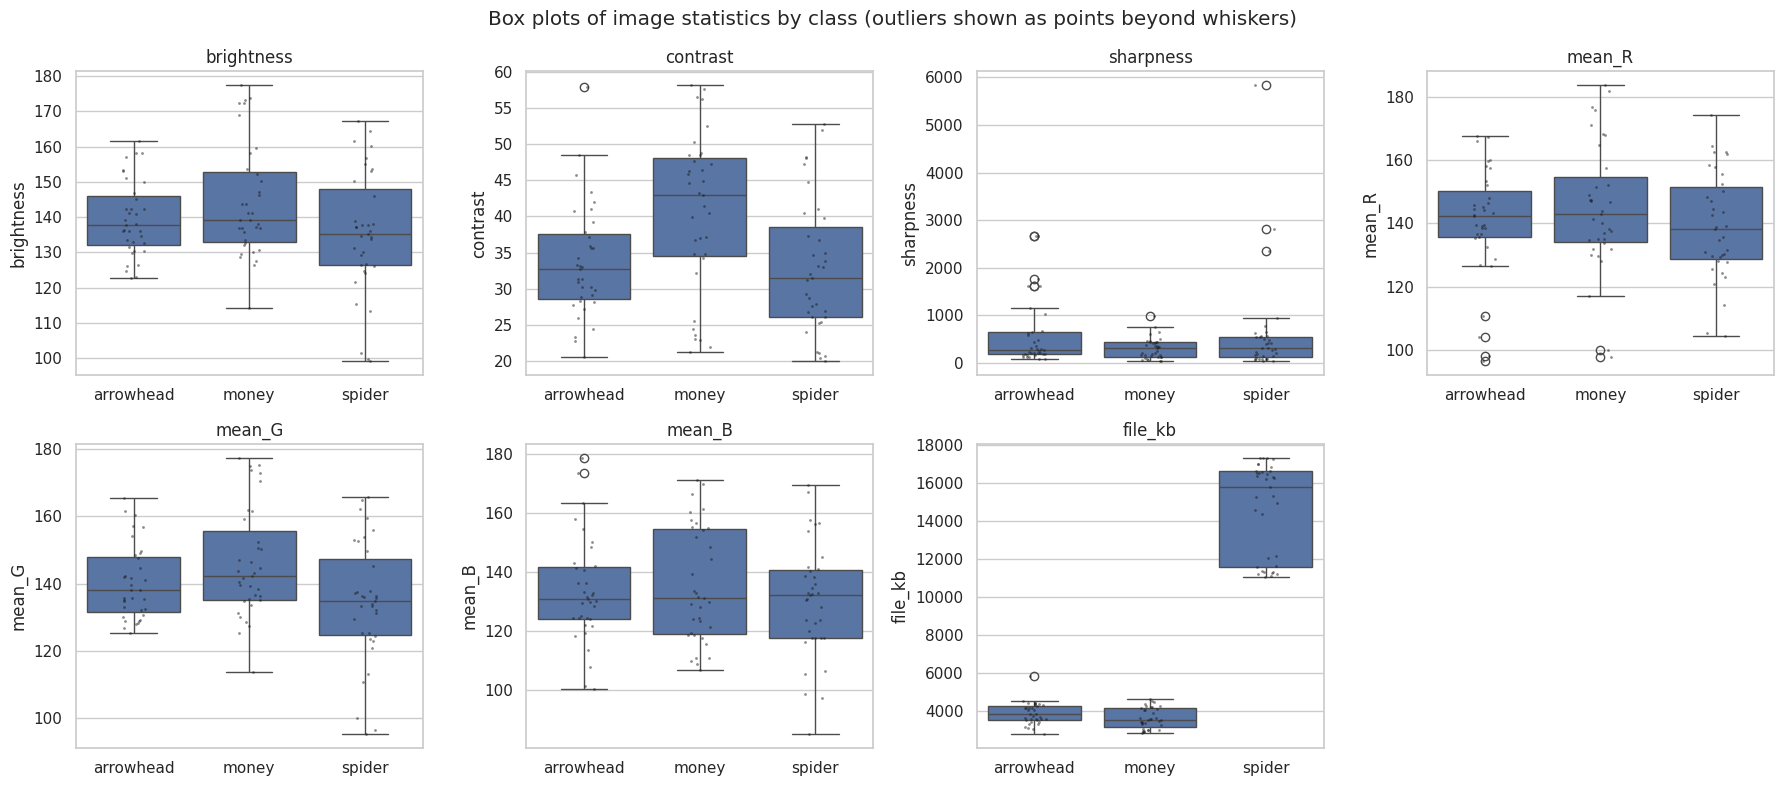

Very blurry images: []


In [5]:
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)

stat_cols = ['brightness', 'contrast', 'sharpness', 'mean_R', 'mean_G', 'mean_B', 'file_kb']
out_tbl = pd.DataFrame({c: iqr_outliers(df[c]) for c in stat_cols})
print('Number of IQR outliers per attribute:'); print(out_tbl.sum().to_string())
flag = out_tbl.any(axis=1)
print(f'\nImages flagged on at least one attribute: {int(flag.sum())}')
display(df.loc[flag, ['file_name', 'label'] + stat_cols].round(1))

fig, axes = plt.subplots(2, 4, figsize=(18, 8)); axes = axes.ravel()
for ax, c in zip(axes, stat_cols):
    sns.boxplot(data=df, x='label', y=c, ax=ax); sns.stripplot(data=df, x='label', y=c, ax=ax, color='k', size=2, alpha=.5)
    ax.set_title(c); ax.set_xlabel('')
axes[-1].axis('off'); plt.suptitle('Box plots of image statistics by class (outliers shown as points beyond whiskers)'); plt.tight_layout(); plt.show()

# --- optional treatment: drop extremely blurry images. Set True after looking at them.
DROP_BLURRY = False
blurry = iqr_outliers(df['sharpness']) & (df['sharpness'] < df['sharpness'].median())
print('Very blurry images:', df.loc[blurry, 'file_name'].tolist())
if DROP_BLURRY and blurry.any():
    keep = ~blurry.values
    df = df[keep].reset_index(drop=True); images = images[keep]; pad_masks = pad_masks[keep]
    print('Dropped; new shape:', df.shape)

### 5. Feature (attribute) distributions – histograms and box plots

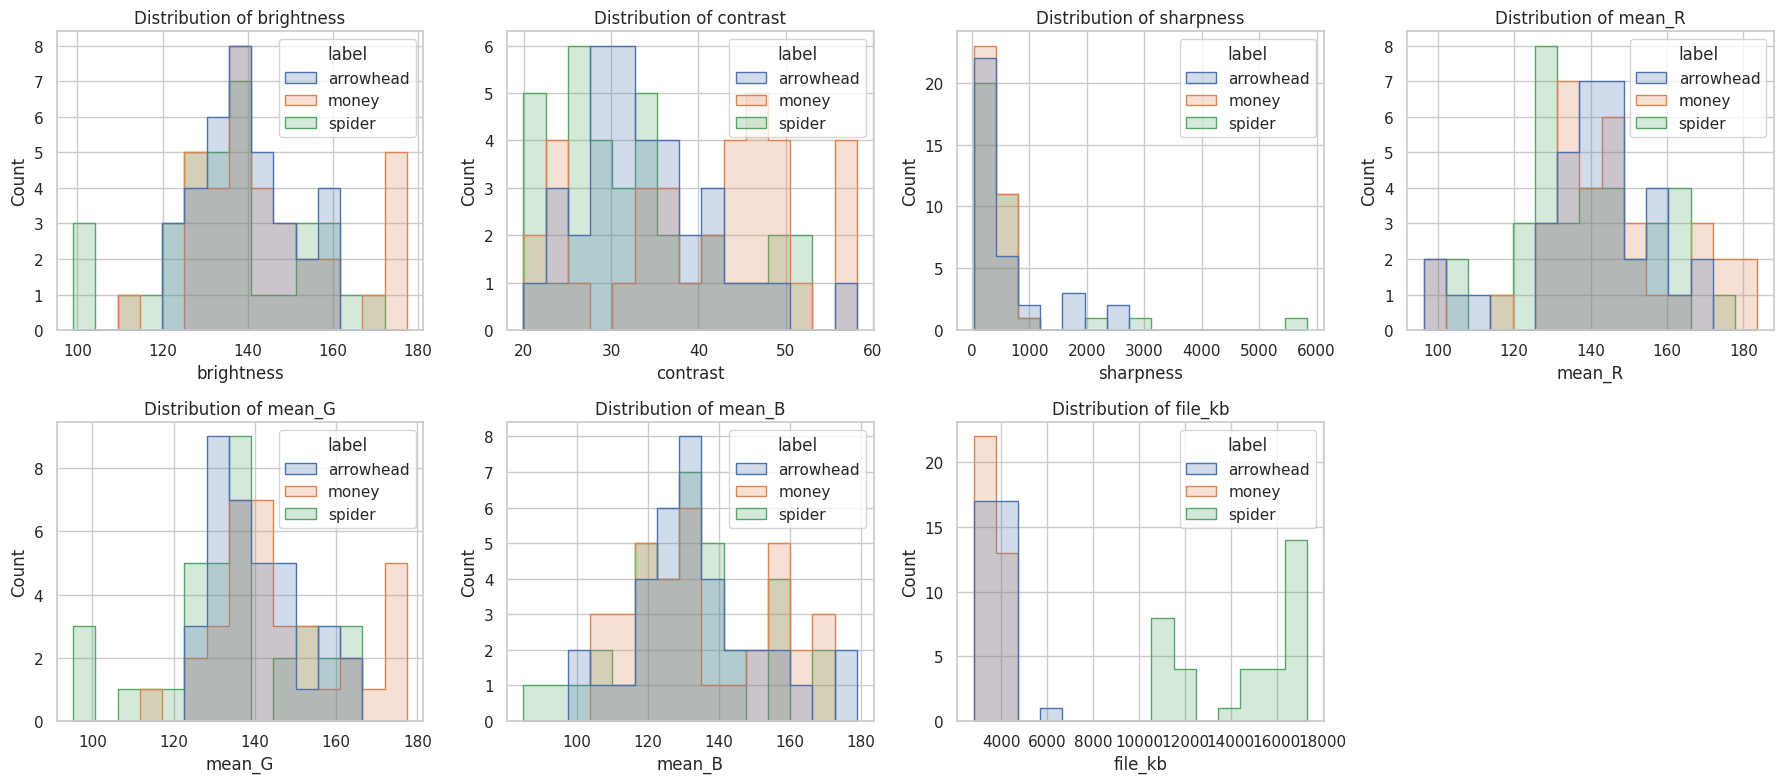

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8)); axes = axes.ravel()
for ax, c in zip(axes, stat_cols):
    sns.histplot(data=df, x=c, hue='label', element='step', bins=15, ax=ax)
    ax.set_title(f'Distribution of {c}')
axes[-1].axis('off'); plt.tight_layout(); plt.show()

### 6. Correlation analysis between numerical attributes

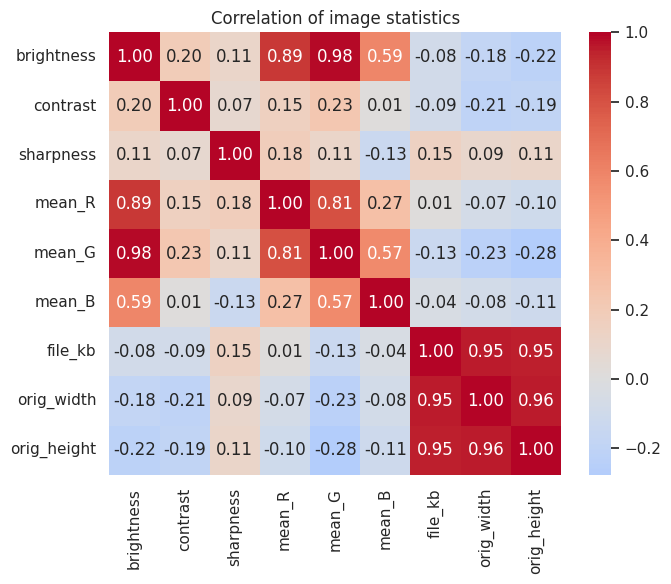

In [7]:
plt.figure(figsize=(7, 6))
sns.heatmap(df[stat_cols + ['orig_width', 'orig_height']].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation of image statistics'); plt.tight_layout(); plt.show()

### 7. Class label distribution and balance

label
arrowhead    35
money        35
spider       35

Imbalance ratio (max/min): 1.0


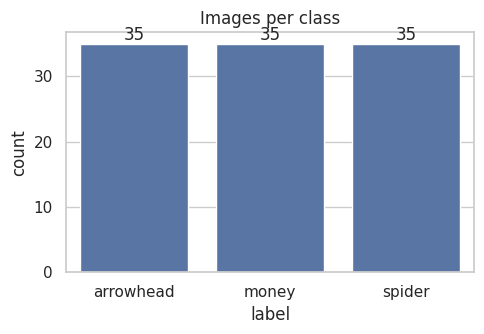

In [8]:
counts = df['label'].value_counts()
print(counts.to_string()); print('\nImbalance ratio (max/min):', round(counts.max() / counts.min(), 2))
plt.figure(figsize=(5, 3.5)); ax = sns.countplot(data=df, x='label', order=counts.index)
ax.bar_label(ax.containers[0]); plt.title('Images per class'); plt.tight_layout(); plt.show()

### 8. Representative samples from every class

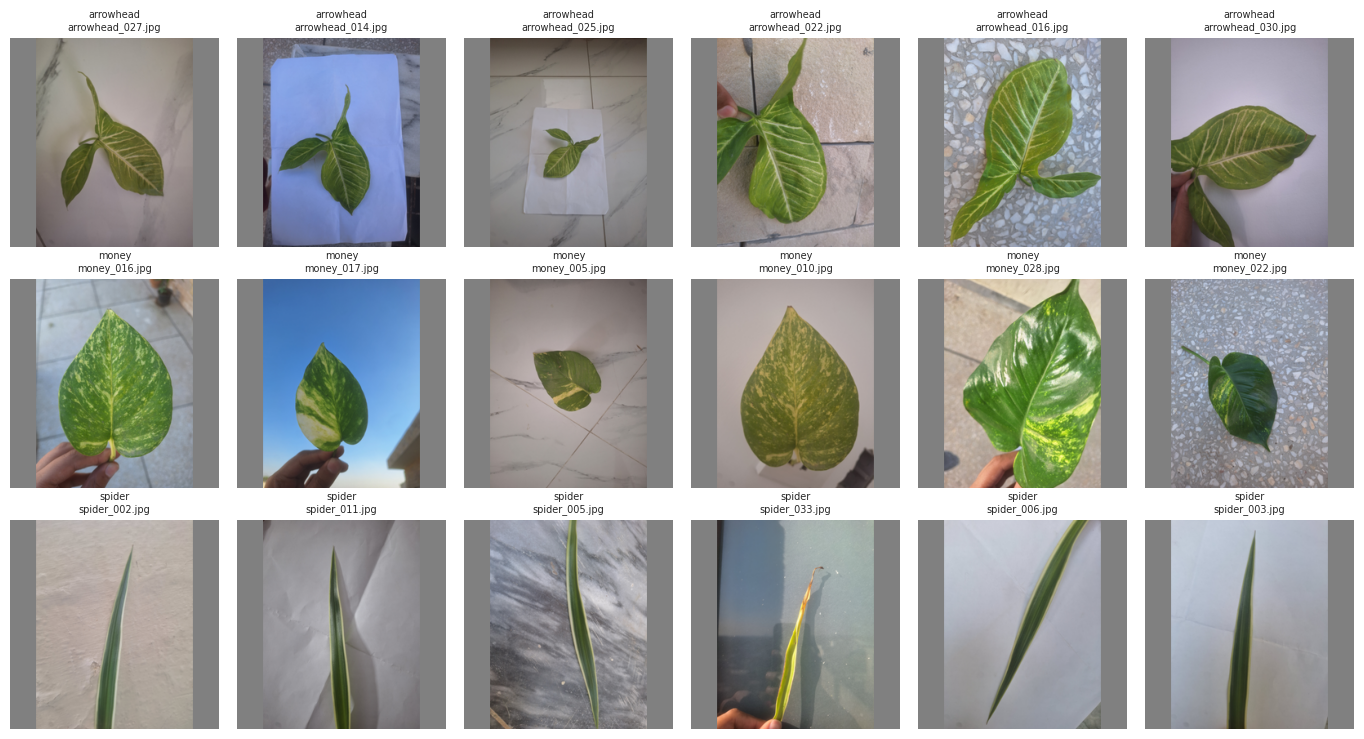

In [9]:
classes = sorted(df['label'].unique())
rng = np.random.RandomState(SEED)
n = 6
fig, axes = plt.subplots(len(classes), n, figsize=(2.3 * n, 2.5 * len(classes)))
for r, cls in enumerate(classes):
    pick = rng.choice(np.where(df['label'] == cls)[0], n, replace=False)
    for c, i in enumerate(pick):
        axes[r, c].imshow(images[i]); axes[r, c].axis('off')
        axes[r, c].set_title(f'{cls}\n{df.file_name[i]}', fontsize=7)
plt.tight_layout(); plt.show()

### 9. Image-specific EDA: dimensions, colour distribution, brightness and quality

Original image sizes (width x height) and counts:
orig_width  orig_height
3060        4080           68
6120        8160           34
4080        3060            2
8160        6120            1

Orientation counts:
orientation  landscape  portrait
label                           
arrowhead            1        34
money                1        34
spider               1        34


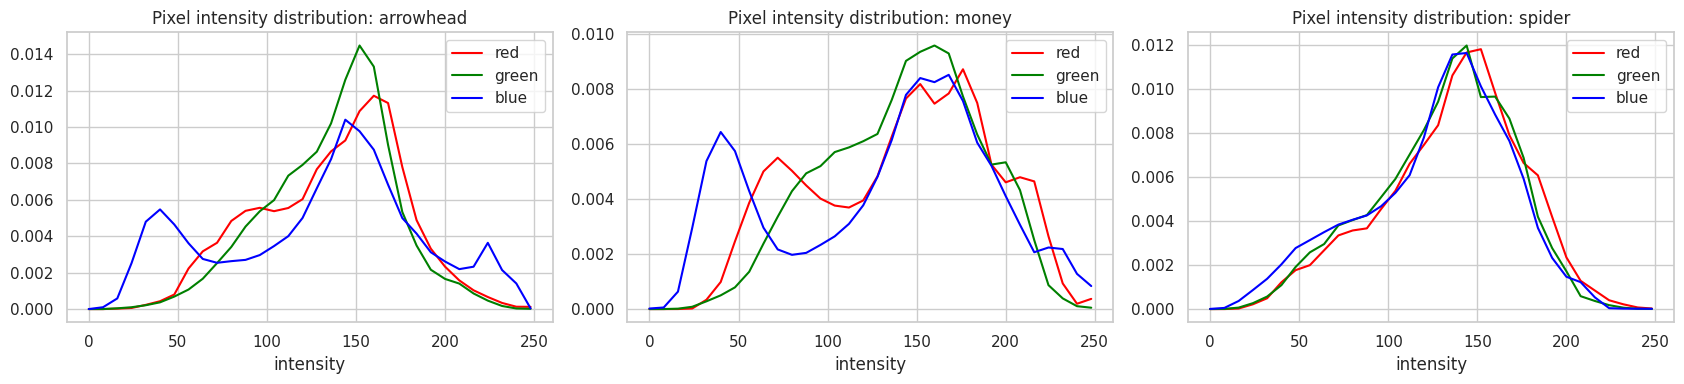

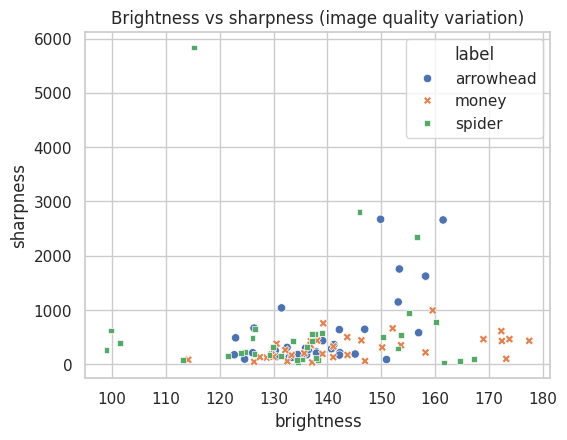

In [10]:
df['orientation'] = np.where(df.orig_width >= df.orig_height, 'landscape', 'portrait')
print('Original image sizes (width x height) and counts:')
print(df.groupby(['orig_width', 'orig_height']).size().sort_values(ascending=False).head(10).to_string())
print('\nOrientation counts:'); print(df.groupby(['label', 'orientation']).size().unstack(fill_value=0))

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
# average RGB intensity histogram per class (letterbox padding excluded)
for ax, cls in zip(axes, classes):
    sel = np.where(df.label == cls)[0]
    px = np.concatenate([images[i][pad_masks[i]] for i in sel])
    for ch, col in enumerate(['red', 'green', 'blue']):
        hist, edges = np.histogram(px[:, ch], bins=32, range=(0, 256), density=True)
        ax.plot(edges[:-1], hist, color=col, label=col)
    ax.set_title(f'Pixel intensity distribution: {cls}'); ax.set_xlabel('intensity'); ax.legend()
plt.tight_layout(); plt.show()

plt.figure(figsize=(6, 4.5))
sns.scatterplot(data=df, x='brightness', y='sharpness', hue='label', style='label')
plt.title('Brightness vs sharpness (image quality variation)'); plt.show()

**Optional – compare with my image log sheet.** If the log (`Leaf_Dataset_Image_Log.xlsx`) is in Drive and its *File Name* column matches the real file names,
it is merged so I can check whether brightness really changes with the lighting condition I recorded.

105 / 105 images matched with the log sheet


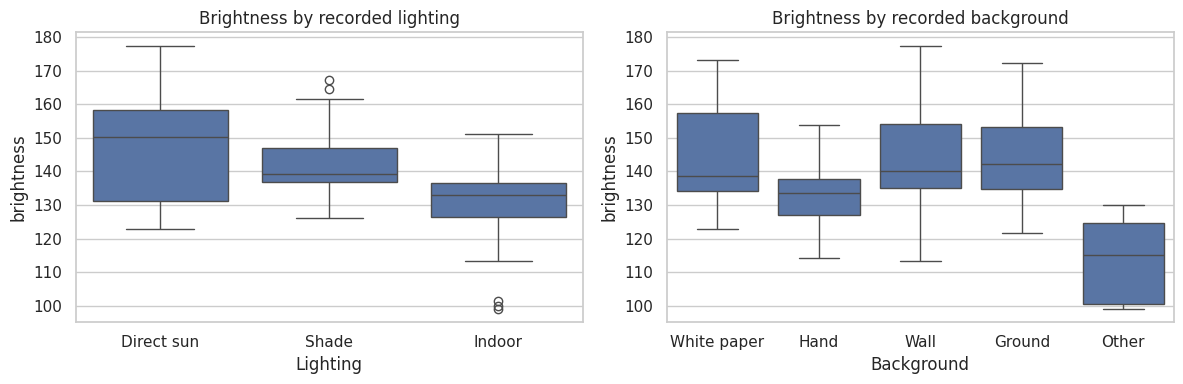

Lighting,Direct sun,Indoor,Shade
label,,,
arrowhead,12,12,11
money,12,12,11
spider,12,13,10


In [13]:
if LOG_PATH and os.path.exists(LOG_PATH):
    log = pd.read_excel(LOG_PATH, sheet_name='Image Log')
    log['key'] = log['File Name'].astype(str).str.lower().str.strip()
    tmp = df.assign(key=df['file_name'].str.lower().str.strip()).merge(
        log[['key', 'Lighting', 'Background', 'Distance', 'Orientation']], on='key', how='left')
    matched = int(tmp['Lighting'].notna().sum())
    print(f'{matched} / {len(df)} images matched with the log sheet')
    if matched >= 0.5 * len(df):
        df = tmp.drop(columns='key').rename(columns={'Orientation': 'leaf_orientation'})
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        sns.boxplot(data=df, x='Lighting', y='brightness', ax=axes[0]); axes[0].set_title('Brightness by recorded lighting')
        sns.boxplot(data=df, x='Background', y='brightness', ax=axes[1]); axes[1].set_title('Brightness by recorded background')
        plt.tight_layout(); plt.show()
        display(pd.crosstab(df['label'], df['Lighting']))
    else:
        print('Too few matches - rename photos to the File Name column (e.g. spider_001.jpg) to use this step.')
else:
    print('Log sheet not found - skipping (not required).')

**EDA observations (write in your own words after running):**
* Dataset size, class balance, any duplicates/outliers found and what I did about them.
* Image dimensions: are all photos the same size/orientation? (This is why resizing is needed.)
* Brightness/contrast/sharpness differences between classes and lighting conditions; any blurry images.
* Colour distributions: do the classes differ in their green/yellow balance?

# Phase II – Preprocessing and Feature Engineering

## A. Preprocessing (what, why, parameters)
| Step | Why | Parameters |
|---|---|---|
| EXIF orientation fix | Phone photos are stored rotated; without this portrait photos load sideways | `ImageOps.exif_transpose` |
| Resize + letterbox | Phone images are ~4000×3000 px and differ in orientation; features (HOG, shape) need a fixed size, and plain resizing would distort leaf shape | longest side → 256 px (LANCZOS), padded to 256×256 with grey (128,128,128) |
| Remove duplicates | Prevent train/test leakage | MD5 hash of file |
| Leaf segmentation | Backgrounds vary (paper, ground, hand, wall). Features computed on the whole image would mostly describe the background, not the leaf | Excess-Green index `ExG = 2g − r − b` on chromatic coordinates, Otsu threshold, closing (disk 5), opening (disk 3), hole filling, largest connected component |
| Feature scaling | Features have very different ranges; KNN/K-Means/Agglomerative are distance based | `StandardScaler` (fit on train only for KNN) |

Segmentation is checked visually below. If a mask is unreasonable (<2 % or >90 % of the image) the code falls back to the whole image and marks `seg_ok = False`.

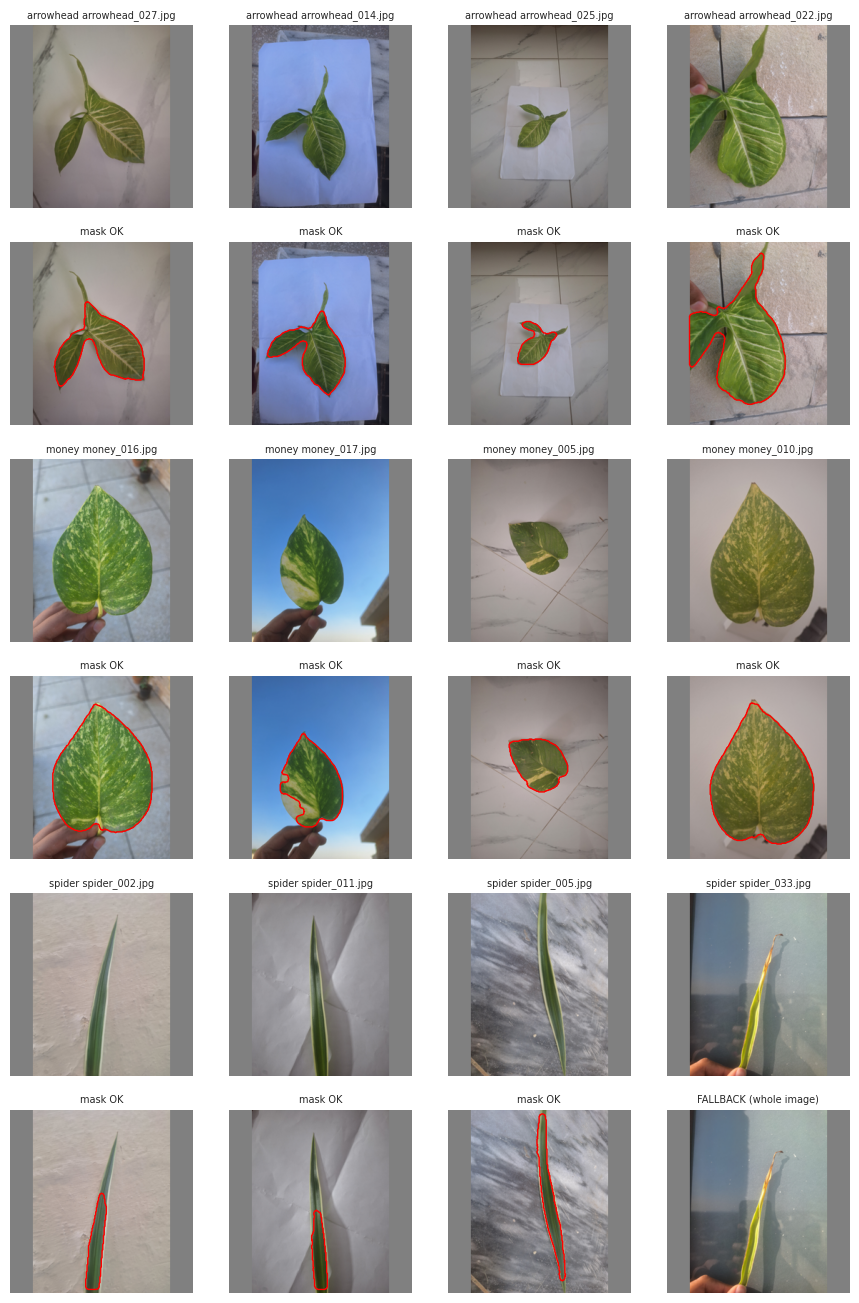

In [14]:
from skimage import color, filters, morphology, measure
from skimage.feature import canny, local_binary_pattern, hog

def segment_leaf(rgb):
    """Return (mask, ok). Excess-green + Otsu, cleaned with morphology; largest component = the leaf."""
    f = rgb.astype(np.float32); s = f.sum(axis=2) + 1e-6
    r, g, b = f[..., 0] / s, f[..., 1] / s, f[..., 2] / s
    exg = 2 * g - r - b
    m = exg > filters.threshold_otsu(exg)
    m = ndi.binary_closing(m, structure=morphology.disk(5))
    m = ndi.binary_opening(m, structure=morphology.disk(3))
    m = ndi.binary_fill_holes(m)
    lab, nlab = ndi.label(m)
    if nlab == 0:
        return np.ones(m.shape, bool), False
    sizes = np.bincount(lab.ravel()); sizes[0] = 0
    m = lab == sizes.argmax()
    if not (0.02 < m.mean() < 0.90):
        return np.ones(m.shape, bool), False
    return m, True

# --- visual check of the segmentation: 4 random images per class, original (top) and leaf outline (bottom)
rng = np.random.RandomState(SEED)
fig, axes = plt.subplots(2 * len(classes), 4, figsize=(9, 4.4 * len(classes)))
for k, cls in enumerate(classes):
    for c, i in enumerate(rng.choice(np.where(df.label == cls)[0], 4, replace=False)):
        m, ok = segment_leaf(images[i])
        axes[2 * k, c].imshow(images[i]); axes[2 * k, c].set_title(f'{cls} {df.file_name[i]}', fontsize=7)
        axes[2 * k + 1, c].imshow(images[i]); axes[2 * k + 1, c].contour(m, [0.5], colors='red', linewidths=1)
        axes[2 * k + 1, c].set_title('mask OK' if ok else 'FALLBACK (whole image)', fontsize=7)
for a in axes.ravel(): a.axis('off')
plt.tight_layout(); plt.show()

## B. Feature extraction – 19 numerical features per image

| Group | Feature | What it represents | How it helps separate classes |
|---|---|---|---|
| **Colour** (leaf pixels only) | `mean_R`, `mean_G`, `mean_B` | average colour of the leaf | money plant has yellow/white patches (higher R, B); plain green leaves have high G |
| | `mean_H`, `mean_S`, `mean_V` | hue, saturation, brightness in HSV | hue separates yellow-green from deep green; saturation shows how vivid/pale the leaf is |
| | `std_V` | spread of brightness inside the leaf | variegated or veined leaves have a larger spread than uniform ones |
| | `green_ratio` | G / (R+G+B) | normalised greenness, less sensitive to lighting than raw G |
| **Texture** | `edge_density` | fraction of leaf-interior pixels that are Canny edges | veins, wrinkles and patches create many edges; smooth glossy leaves few |
| | `lbp_entropy` | entropy of the Local Binary Pattern histogram (P=8, R=1, uniform) | high for irregular/rough texture, low for smooth surfaces |
| | `lbp_nonuniform` | share of non-uniform LBP patterns (noisy/irregular micro-texture) | distinguishes smooth from rough/hairy surfaces |
| **Gradient** | `hog_mean`, `hog_std` | mean and spread of the Histogram of Oriented Gradients descriptor (9 orientations, 16×16 cells) of the masked leaf | describes how strong and how organised the edge directions are (long straight edges of a spider leaf vs. curved heart outline) |
| **Shape** | `area_ratio` | leaf area / image area | size of leaf in frame (also depends on distance) |
| | `elongation` | minor axis / major axis of the fitted ellipse | very small for long thin spider-plant leaves, larger for broad leaves |
| | `solidity` | area / convex-hull area | lobed or arrow-shaped leaves have lower solidity than round ones |
| | `eccentricity` | how stretched the fitted ellipse is | complements elongation |
| | `extent` | area / bounding-box area | triangular (arrowhead) leaves fill less of their box than rectangular ones |
| | `circularity` | 4πA / P² | 1 for a circle, small for thin or jagged outlines |

**Note:** the full HOG vector has thousands of values, so it is summarised with mean/std to keep the feature space small enough for KNN and clustering (distance-based methods degrade in very high dimensions).

In [15]:
def extract_features(rgb):
    mask, ok = segment_leaf(rgb)
    f = {}
    px = rgb[mask].astype(np.float32)
    hsv = color.rgb2hsv(rgb)[mask]
    f['mean_R'], f['mean_G'], f['mean_B'] = px.mean(axis=0)
    f['mean_H'], f['mean_S'], f['mean_V'] = hsv.mean(axis=0)
    f['std_V'] = hsv[:, 2].std()
    f['green_ratio'] = px[:, 1].mean() / (px.sum(axis=1).mean() + 1e-6)

    gray = color.rgb2gray(rgb)
    inner = ndi.binary_erosion(mask, structure=morphology.disk(3))      # exclude the outline itself
    if inner.sum() < 50: inner = mask
    f['edge_density'] = canny(gray, sigma=1.5)[inner].mean()

    lbp = local_binary_pattern((gray * 255).astype(np.uint8), P=8, R=1, method='uniform')
    hist = np.bincount(lbp[inner].astype(int), minlength=10).astype(float); hist /= hist.sum()
    f['lbp_entropy'] = -(hist[hist > 0] * np.log2(hist[hist > 0])).sum()
    f['lbp_nonuniform'] = hist[9]

    hv = hog(gray * mask, orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2), feature_vector=True)
    f['hog_mean'], f['hog_std'] = hv.mean(), hv.std()

    p = measure.regionprops(mask.astype(int))[0]
    f['area_ratio'] = mask.mean()
    f['elongation'] = p.minor_axis_length / (p.major_axis_length + 1e-6)
    f['solidity'] = p.solidity
    f['eccentricity'] = p.eccentricity
    f['extent'] = p.extent
    f['circularity'] = min(1.0, 4 * np.pi * p.area / (p.perimeter ** 2 + 1e-6))
    f['seg_ok'] = ok
    return f

feat = pd.DataFrame([extract_features(im) for im in images])
feat.insert(0, 'file_name', df['file_name'].values)
feat['label'] = df['label'].values
FEATURES = [c for c in feat.columns if c not in ('file_name', 'label', 'seg_ok')]
print('Feature matrix:', feat[FEATURES].shape, '| segmentation fallback used for', int((~feat.seg_ok).sum()), 'images')
display(feat.head())
display(feat.groupby('label')[FEATURES].mean().T.round(3))

Feature matrix: (105, 19) | segmentation fallback used for 6 images


,file_name,mean_R,mean_G,mean_B,mean_H,mean_S,mean_V,std_V,green_ratio,edge_density,...,hog_mean,hog_std,area_ratio,elongation,solidity,eccentricity,extent,circularity,seg_ok,label
0,arrowhead_001.jpg,81.716682,106.430725,57.478451,0.259309,0.466862,0.417559,0.078658,0.433304,0.125697,...,0.059699,0.107227,0.299881,0.468738,0.851886,0.883337,0.578915,0.499886,True,arrowhead
1,arrowhead_002.jpg,167.960907,182.706879,61.997158,0.191799,0.672138,0.718568,0.180972,0.442749,0.186944,...,0.019628,0.071041,0.064392,0.545109,0.821171,0.838365,0.493625,0.500942,True,arrowhead
2,arrowhead_003.jpg,138.135483,153.551361,53.924614,0.192486,0.664325,0.603554,0.147559,0.444289,0.167191,...,0.050399,0.103891,0.244507,0.638136,0.851028,0.769924,0.630171,0.490626,True,arrowhead
3,arrowhead_004.jpg,98.219223,113.738213,44.514416,0.204699,0.613631,0.446484,0.158169,0.443472,0.138672,...,0.014146,0.064194,0.033340,0.710613,0.762387,0.703583,0.446739,0.429522,True,arrowhead
4,arrowhead_005.jpg,80.672585,100.439301,66.291168,0.275873,0.358802,0.395011,0.085217,0.405974,0.080709,...,0.064715,0.112259,0.359085,0.580268,0.965456,0.814426,0.655442,0.723635,True,arrowhead


label,arrowhead,money,spider
mean_R,105.402,88.959,94.650
mean_G,119.341,106.063,103.770
mean_B,53.664,51.861,77.236
mean_H,0.202,0.229,0.243
mean_S,0.551,0.508,0.327
mean_V,0.470,0.419,0.417
std_V,0.101,0.095,0.111
green_ratio,0.427,0.428,0.385
edge_density,0.126,0.084,0.078
lbp_entropy,3.179,3.247,2.909


### Do the features separate the classes? (visual check)

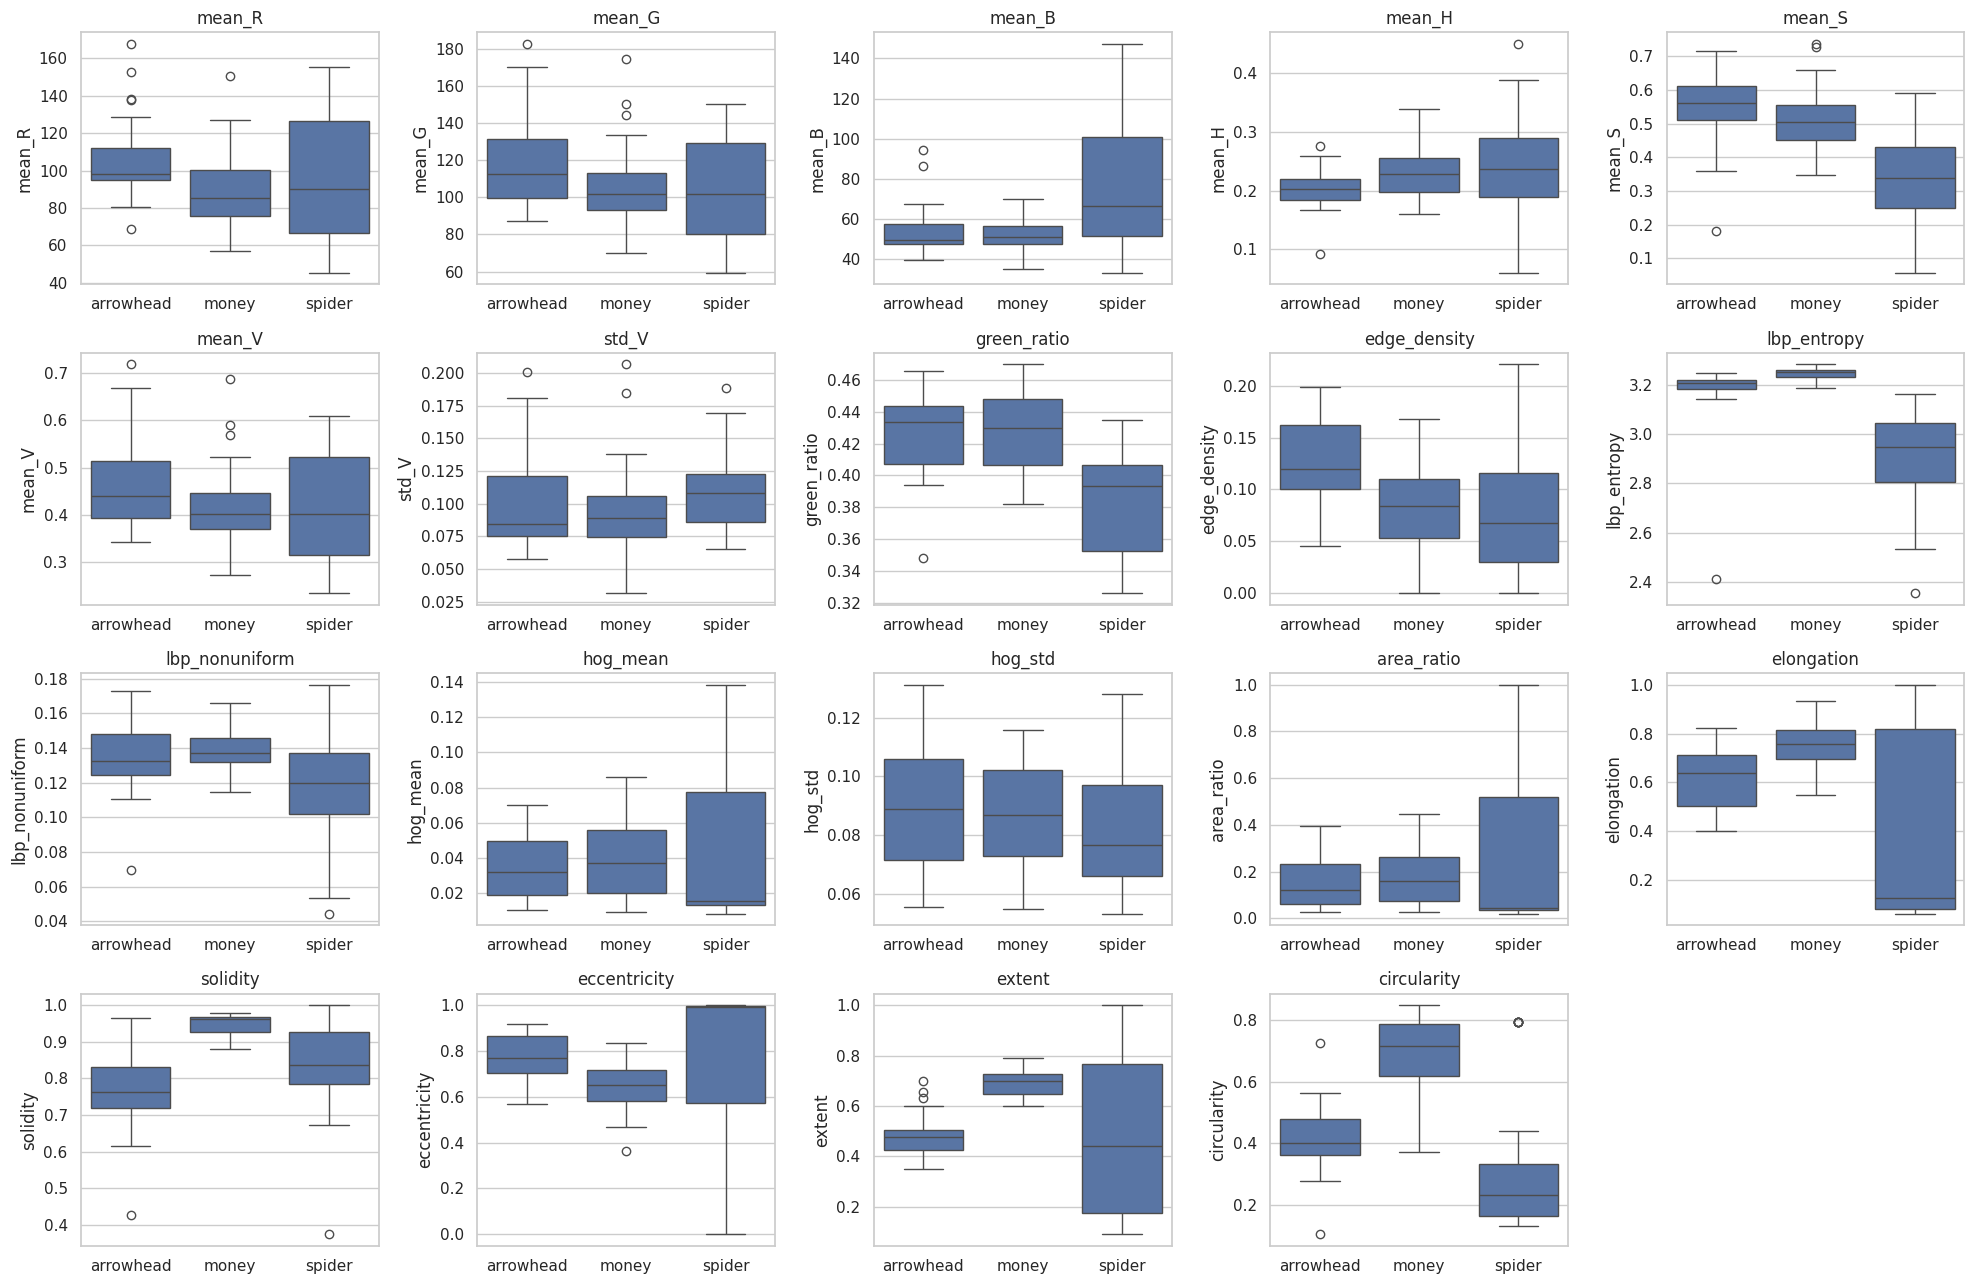

,F_score,p_value
lbp_entropy,70.2958,0.0000
circularity,51.1972,0.0000
mean_S,36.9696,0.0000
solidity,33.5728,0.0000
green_ratio,28.1261,0.0000
elongation,19.0468,0.0000
mean_B,15.2282,0.0000
extent,11.9041,0.0000
edge_density,10.3723,0.0001
lbp_nonuniform,9.8721,0.0001


In [16]:
fig, axes = plt.subplots(4, 5, figsize=(20, 13)); axes = axes.ravel()
for ax, c in zip(axes, FEATURES):
    sns.boxplot(data=feat, x='label', y=c, ax=ax); ax.set_title(c); ax.set_xlabel('')
for ax in axes[len(FEATURES):]: ax.axis('off')
plt.tight_layout(); plt.show()

# ANOVA F-score: only used to EXPLAIN which features differ between classes (labels are NOT used to pick features for clustering)
from sklearn.feature_selection import f_classif
F, pval = f_classif(feat[FEATURES], feat['label'])
rank = pd.DataFrame({'F_score': F, 'p_value': pval}, index=FEATURES).sort_values('F_score', ascending=False)
display(rank.round(4))

### Feature selection (unsupervised): remove near-duplicate features
Two features with |correlation| > 0.95 carry almost the same information and double-count it in distance calculations.
Using only feature–feature correlation keeps the selection **label-free**, so the same feature set is fair for KNN, K-Means and Agglomerative.

Dropped (|r| > 0.95 with another feature): ['mean_V', 'area_ratio']
Using 17 features: ['mean_R', 'mean_G', 'mean_B', 'mean_H', 'mean_S', 'std_V', 'green_ratio', 'edge_density', 'lbp_entropy', 'lbp_nonuniform', 'hog_mean', 'hog_std', 'elongation', 'solidity', 'eccentricity', 'extent', 'circularity']


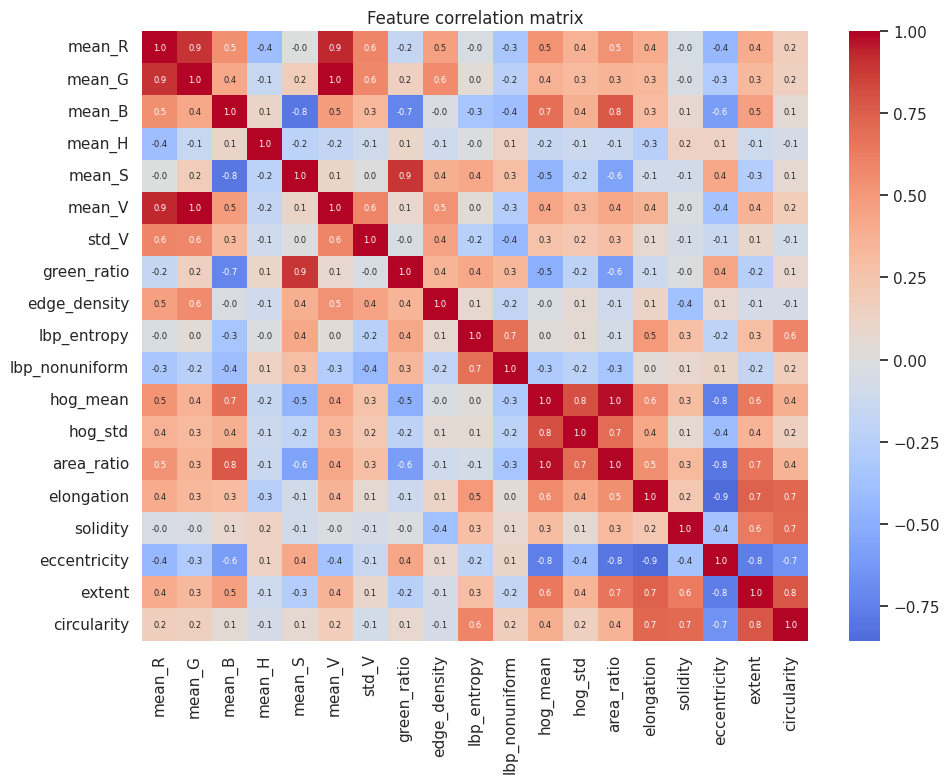

NaN values: 0 | duplicate feature rows: 0
Saved leaf_features.csv and leaf_image_metadata.csv (download these for submission)


In [17]:
corr = feat[FEATURES].corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
to_drop = [c for c in upper.columns if (upper[c] > 0.95).any()]
SELECTED = [c for c in FEATURES if c not in to_drop]
print('Dropped (|r| > 0.95 with another feature):', to_drop)
print(f'Using {len(SELECTED)} features:', SELECTED)

plt.figure(figsize=(10, 8)); sns.heatmap(feat[FEATURES].corr(), cmap='coolwarm', center=0, annot=True, fmt='.1f', annot_kws={'size': 6})
plt.title('Feature correlation matrix'); plt.tight_layout(); plt.show()

# data-quality checks on the final feature table
print('NaN values:', int(feat[SELECTED].isna().sum().sum()), '| duplicate feature rows:', int(feat[SELECTED].duplicated().sum()))
feat[SELECTED] = feat[SELECTED].fillna(feat[SELECTED].median())
feat.to_csv('leaf_features.csv', index=False); df.drop(columns=['md5', 'path']).to_csv('leaf_image_metadata.csv', index=False)
print('Saved leaf_features.csv and leaf_image_metadata.csv (download these for submission)')

# Phase III – KNN Classification (supervised)

**How KNN works:** to classify a new leaf, compute its distance to every training leaf in feature space, take the **K nearest**, and predict the majority class among them.
No model is "trained"; the training data is the model. Parameters I tune:
* `K` – small K follows noise (high variance); large K blurs class boundaries (high bias).
* `metric` – **Euclidean** (straight-line, penalises one big difference) vs **Manhattan** (sum of absolute differences, less sensitive to single outlying features).

**Protocol (no leakage):**
1. Stratified 75/25 train/test split (class proportions preserved).
2. `StandardScaler` is inside a `Pipeline`, so it is fitted only on training data (and only on the training part of each CV fold), then applied to test data.
3. Configurations are compared with **5-fold stratified cross-validation on the training set only**. The test set is touched once, for the final evaluation. (With ~100 images the test set is tiny, so a single test split is noisy – I also report repeated CV on all data.)

Train: (78, 17) {'arrowhead': 26, 'money': 26, 'spider': 26} | Test: (27, 17) {'spider': 9, 'money': 9, 'arrowhead': 9}


,metric,k,cv_acc,cv_std,test_acc,test_macro_f1
0,euclidean,1,0.885,0.073,1.000,1.000
1,euclidean,3,0.898,0.085,0.926,0.927
2,euclidean,5,0.885,0.083,0.926,0.927
3,euclidean,7,0.885,0.083,0.926,0.927
4,euclidean,9,0.873,0.068,0.889,0.891
5,manhattan,1,0.923,0.046,1.000,1.000
6,manhattan,3,0.898,0.085,0.963,0.963
7,manhattan,5,0.898,0.084,0.926,0.927
8,manhattan,7,0.898,0.084,0.926,0.927
9,manhattan,9,0.886,0.072,0.926,0.927


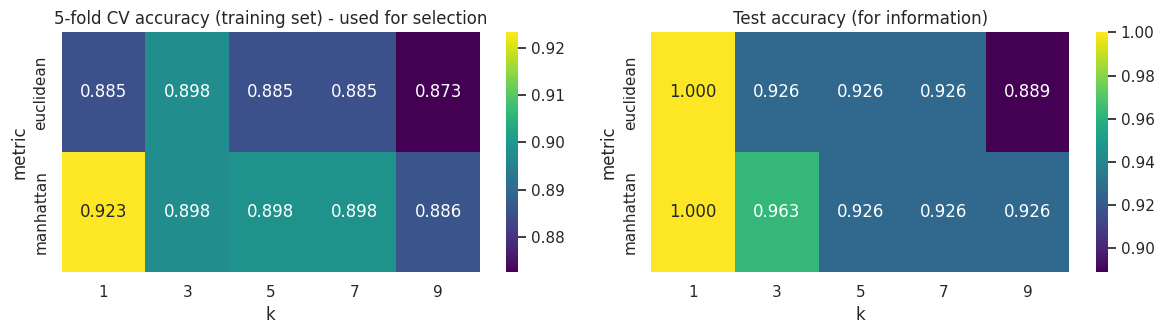

Best configuration by CV: K=1, metric=manhattan  (CV acc 0.923 +/- 0.046)


In [20]:
from sklearn.model_selection import train_test_split, StratifiedKFold, RepeatedStratifiedKFold, cross_val_score, cross_val_predict
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, f1_score)

X = feat[SELECTED].values; y = feat['label'].values
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder().fit(y); y_int = le.transform(y)    # KNN is given integer labels (newer scikit-learn cannot handle text labels in KNN)
idx = np.arange(len(y))
tr_idx, te_idx = train_test_split(idx, test_size=0.25, stratify=y, random_state=SEED)
Xtr, Xte, ytr, yte = X[tr_idx], X[te_idx], y[tr_idx], y[te_idx]
ytr_i = y_int[tr_idx]
print('Train:', Xtr.shape, pd.Series(ytr).value_counts().to_dict(), '| Test:', Xte.shape, pd.Series(yte).value_counts().to_dict())

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rows = []
for metric in ['euclidean', 'manhattan']:
    for k in [1, 3, 5, 7, 9]:
        pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k, metric=metric))
        cv = cross_val_score(pipe, Xtr, ytr_i, cv=cv5, scoring='accuracy')
        pipe.fit(Xtr, ytr_i); pred = le.inverse_transform(pipe.predict(Xte))
        rows.append(dict(metric=metric, k=k, cv_acc=cv.mean(), cv_std=cv.std(),
                         test_acc=accuracy_score(yte, pred), test_macro_f1=f1_score(yte, pred, average='macro')))
res = pd.DataFrame(rows)
display(res.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
sns.heatmap(res.pivot(index='metric', columns='k', values='cv_acc'), annot=True, fmt='.3f', cmap='viridis', ax=axes[0]); axes[0].set_title('5-fold CV accuracy (training set) - used for selection')
sns.heatmap(res.pivot(index='metric', columns='k', values='test_acc'), annot=True, fmt='.3f', cmap='viridis', ax=axes[1]); axes[1].set_title('Test accuracy (for information)')
plt.tight_layout(); plt.show()

best = res.sort_values(['cv_acc', 'k'], ascending=[False, False]).iloc[0]    # ties -> larger K (smoother, more stable)
BEST_K, BEST_METRIC = int(best.k), best.metric
print(f'Best configuration by CV: K={BEST_K}, metric={BEST_METRIC}  (CV acc {best.cv_acc:.3f} +/- {best.cv_std:.3f})')

**Justification of the chosen configuration (write after running):** the selected K/metric was chosen using *cross-validation on the training data only*, not by looking at test accuracy.
Comment on: how accuracy changes with K (K=1 overfitting?), which metric was better and why, and whether differences between configurations are larger than the CV standard deviation (if not, they are effectively tied).

TEST accuracy = 1.000 | macro F1 = 1.000

              precision    recall  f1-score   support

   arrowhead      1.000     1.000     1.000         9
       money      1.000     1.000     1.000         9
      spider      1.000     1.000     1.000         9

    accuracy                          1.000        27
   macro avg      1.000     1.000     1.000        27
weighted avg      1.000     1.000     1.000        27



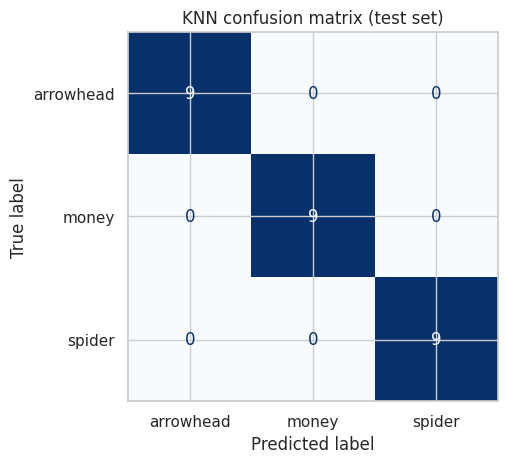

Repeated 5-fold CV accuracy on all data (10 repeats): 0.934 +/- 0.047


In [21]:
best_pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=BEST_K, metric=BEST_METRIC))
best_pipe.fit(Xtr, ytr_i); pred = le.inverse_transform(best_pipe.predict(Xte))
knn_test_acc = accuracy_score(yte, pred)
knn_macro_f1 = f1_score(yte, pred, average='macro')
print(f'TEST accuracy = {knn_test_acc:.3f} | macro F1 = {knn_macro_f1:.3f}\n')
print(classification_report(yte, pred, digits=3))

cm = confusion_matrix(yte, pred, labels=classes)
ConfusionMatrixDisplay(cm, display_labels=classes).plot(cmap='Blues', colorbar=False); plt.title('KNN confusion matrix (test set)'); plt.show()

# More robust estimate than one tiny split: repeated stratified 5-fold CV on ALL data
rcv = cross_val_score(best_pipe, X, y_int, cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED))
print(f'Repeated 5-fold CV accuracy on all data (10 repeats): {rcv.mean():.3f} +/- {rcv.std():.3f}')

### Analysis of incorrectly classified images

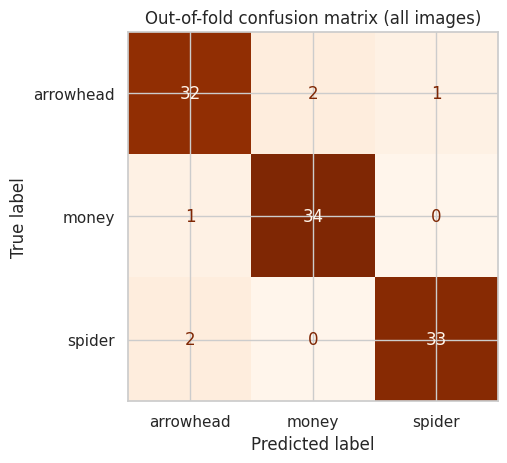

Misclassified (out-of-fold): 6 / 105
Most common confusions (true -> predicted):
(arrowhead, money)     2
(spider, arrowhead)    2
(arrowhead, spider)    1
(money, arrowhead)     1


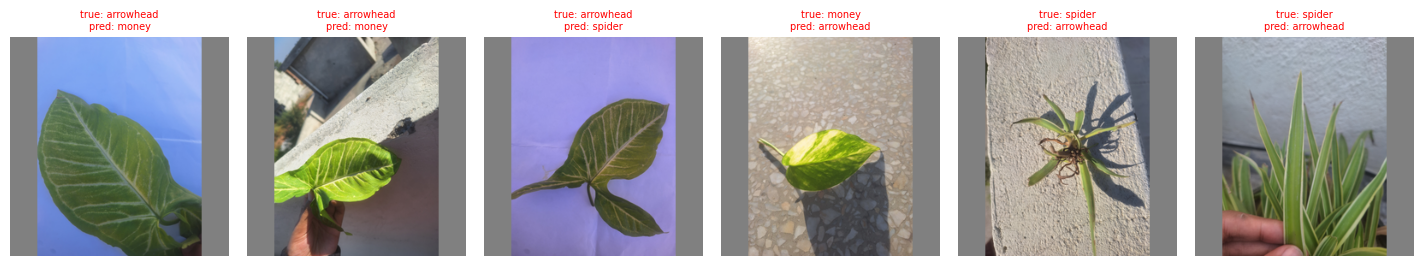

Misclassified test-set images only: []


In [22]:
# out-of-fold predictions on all images give more error examples than the small test set alone
oof = le.inverse_transform(cross_val_predict(best_pipe, X, y_int, cv=cv5))
cm_oof = confusion_matrix(y, oof, labels=classes)
ConfusionMatrixDisplay(cm_oof, display_labels=classes).plot(cmap='Oranges', colorbar=False); plt.title('Out-of-fold confusion matrix (all images)'); plt.show()

wrong = np.where(oof != y)[0]
print(f'Misclassified (out-of-fold): {len(wrong)} / {len(y)}')
pairs = pd.Series([(y[i], oof[i]) for i in wrong]).value_counts()
print('Most common confusions (true -> predicted):'); print(pairs.to_string() if len(pairs) else 'none')

if len(wrong):
    show = wrong[:12]; ncol = 6; nrow = int(np.ceil(len(show) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(2.4 * ncol, 2.7 * nrow), squeeze=False)
    for a in axes.ravel(): a.axis('off')
    for a, i in zip(axes.ravel(), show):
        a.imshow(images[i]); a.set_title(f'true: {y[i]}\npred: {oof[i]}', fontsize=7, color='red')
    plt.tight_layout(); plt.show()
    print('Misclassified test-set images only:', [df.file_name[tr_i] for tr_i in te_idx[pred != yte]])

**Interpretation (write after running):** which classes are hard to distinguish? Look at the confusion pairs above and at the images – typical reasons are
similar leaf shape (arrowhead vs money plant), very similar green colour, strong shadows or bright sun changing colour features, a failed leaf segmentation, blur, or a leaf photographed from far away.

# Phase IV – K-Means Clustering (unsupervised)

**How K-Means works:** choose K centroids → assign every point to its nearest centroid → move each centroid to the mean of its points → repeat until assignments stop changing.
It minimises **WCSS / inertia** = Σ squared distance of each point to its centroid. It assumes roughly round, similar-sized clusters and needs K in advance.

* `n_init=10`: run 10 random starts and keep the best (K-Means can get stuck in poor local minima).
* **Elbow method:** plot inertia vs K; look for the bend where extra clusters stop reducing inertia much.
* **Silhouette score** (−1…1): how much closer a point is to its own cluster than to the nearest other cluster. Higher is better.
* Class labels are **not** used for fitting. Features are standardised first (K-Means uses Euclidean distance).

,K,WCSS (inertia),Silhouette
0,2,1324.721,0.444
1,3,1016.674,0.311
2,4,858.198,0.237
3,5,755.009,0.245
4,6,656.674,0.247
5,7,624.108,0.241
6,8,600.712,0.206


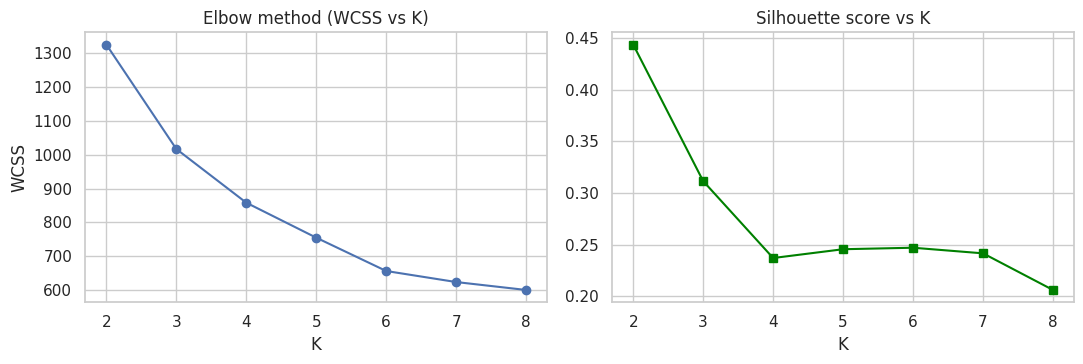

K with the highest silhouette score: 2


In [23]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score

Xs = StandardScaler().fit_transform(X)       # unsupervised: scaling uses features only
ks = list(range(2, 9)); inertia, sil = [], []
for k in ks:
    km_ = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Xs)
    inertia.append(km_.inertia_); sil.append(silhouette_score(Xs, km_.labels_))
kres = pd.DataFrame({'K': ks, 'WCSS (inertia)': inertia, 'Silhouette': sil}); display(kres.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(ks, inertia, 'o-'); axes[0].set_title('Elbow method (WCSS vs K)'); axes[0].set_xlabel('K'); axes[0].set_ylabel('WCSS')
axes[1].plot(ks, sil, 's-', color='green'); axes[1].set_title('Silhouette score vs K'); axes[1].set_xlabel('K')
plt.tight_layout(); plt.show()
print('K with the highest silhouette score:', ks[int(np.argmax(sil))])

**Choosing K (write after looking at the plots):** state where the elbow is and which K has the best silhouette.
I use **K = 3** for the detailed analysis because the dataset was designed with 3 leaf types, but if the silhouette/elbow prefer another K, discuss why (e.g. variation within a class such as lighting).

In [24]:
K_FINAL = 3
km = KMeans(n_clusters=K_FINAL, n_init=10, random_state=SEED).fit(Xs)
feat['kmeans'] = km.labels_
km_sil = silhouette_score(Xs, km.labels_)
km_ari = adjusted_rand_score(y, km.labels_); km_nmi = normalized_mutual_info_score(y, km.labels_)

print('Observations per cluster:'); print(feat['kmeans'].value_counts().sort_index().to_string())
print('\nAverage (original-scale) feature values per cluster:'); display(feat.groupby('kmeans')[SELECTED].mean().round(3).T)

ct = pd.crosstab(feat['kmeans'], feat['label']); print('Cluster vs actual class:'); display(ct)
dominant = ct.idxmax(axis=1); purity = ct.max(axis=1).sum() / ct.values.sum()
print('Dominant (majority) class of each cluster:', dominant.to_dict())
print(f'\nSilhouette = {km_sil:.3f} | ARI = {km_ari:.3f} | NMI = {km_nmi:.3f} | purity = {purity:.3f}')

Observations per cluster:
kmeans
0    70
1    26
2     9

Average (original-scale) feature values per cluster:


kmeans,0,1,2
mean_R,97.094002,79.816002,138.175003
mean_G,112.831001,93.308998,132.985001
mean_B,52.397999,60.667000,127.931000
mean_H,0.217000,0.250000,0.208000
mean_S,0.533000,0.388000,0.125000
std_V,0.098000,0.100000,0.140000
green_ratio,0.428000,0.400000,0.333000
edge_density,0.107000,0.077000,0.067000
lbp_entropy,3.218000,2.870000,2.979000
lbp_nonuniform,0.136000,0.120000,0.101000


Cluster vs actual class:


label,arrowhead,money,spider
kmeans,,,
0,34,35,1
1,1,0,25
2,0,0,9


Dominant (majority) class of each cluster: {0: 'money', 1: 'spider', 2: 'spider'}

Silhouette = 0.311 | ARI = 0.426 | NMI = 0.574 | purity = 0.657


**Majority-class mapping (for illustration only):** cluster IDs are arbitrary, so a cluster number can't be compared with a class name directly.
For each cluster I count the actual classes inside it and call the most frequent one its *dominant class*. An image is "unexpected" if its actual class differs from the dominant class of its cluster. **Purity** = share of images that agree with their cluster's dominant class. ARI and NMI do not need any mapping.

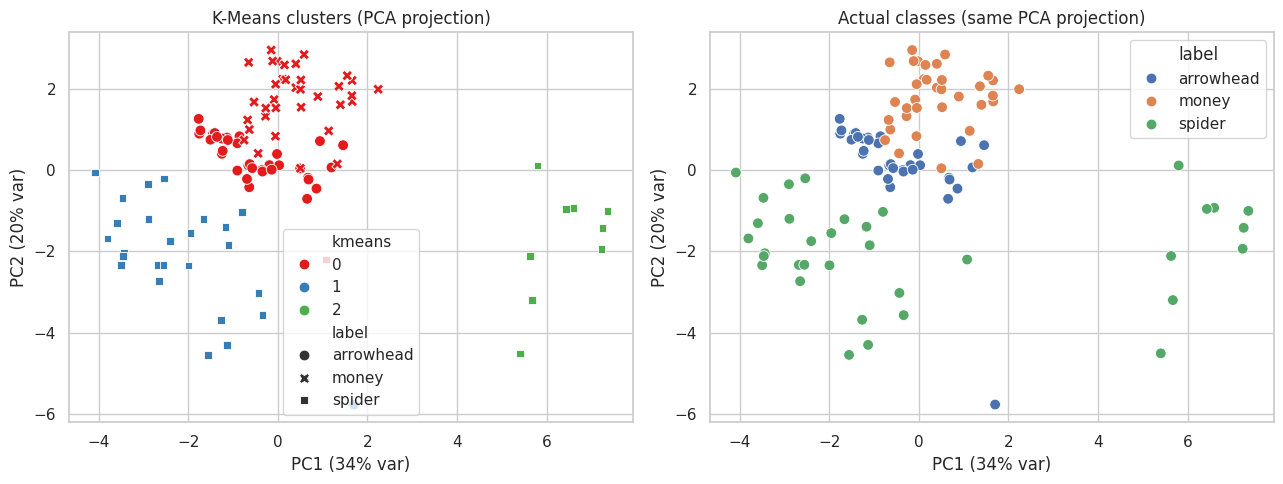

Unexpected observations (class != dominant class of its cluster): 36


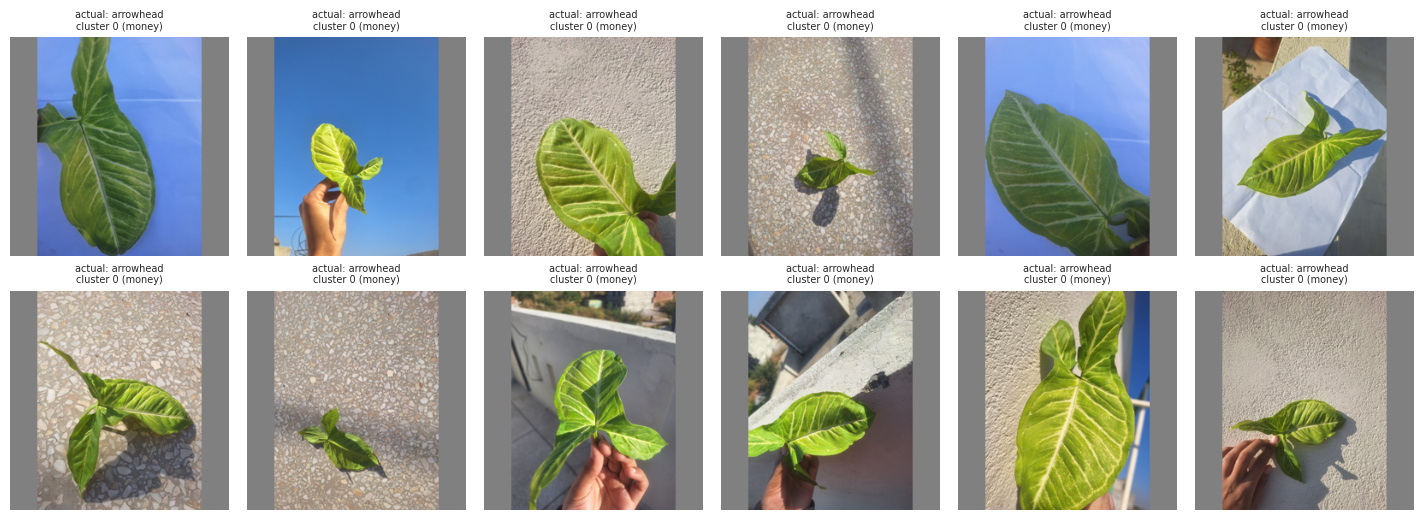

In [25]:
pca = PCA(n_components=2, random_state=SEED); Z2 = pca.fit_transform(Xs)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(x=Z2[:, 0], y=Z2[:, 1], hue=feat['kmeans'], palette='Set1', style=feat['label'], s=60, ax=axes[0]); axes[0].set_title('K-Means clusters (PCA projection)')
sns.scatterplot(x=Z2[:, 0], y=Z2[:, 1], hue=feat['label'], s=60, ax=axes[1]); axes[1].set_title('Actual classes (same PCA projection)')
for a in axes: a.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.0%} var)'); a.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.0%} var)')
plt.tight_layout(); plt.show()

unexp = np.where(feat['label'].values != feat['kmeans'].map(dominant).values)[0]
print(f'Unexpected observations (class != dominant class of its cluster): {len(unexp)}')
if len(unexp):
    show = unexp[:12]; ncol = 6; nrow = int(np.ceil(len(show) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(2.4 * ncol, 2.7 * nrow), squeeze=False)
    for a in axes.ravel(): a.axis('off')
    for a, i in zip(axes.ravel(), show):
        a.imshow(images[i]); a.set_title(f'actual: {y[i]}\ncluster {feat.kmeans[i]} ({dominant[feat.kmeans[i]]})', fontsize=7)
    plt.tight_layout(); plt.show()

**Interpretation (write after running):** do clusters match the leaf types? Which cluster mixes classes, and which features drive it?
Note that K-Means may group by *photo conditions* (bright sun vs shade) rather than by plant if colour features dominate – check the unexpected images.

# Phase V – Agglomerative Hierarchical Clustering (unsupervised)

**How it works (bottom-up):** start with every image as its own cluster → repeatedly merge the two *closest* clusters → until one cluster remains. The merge history is a tree (**dendrogram**); cutting it at a chosen height gives the clusters.
The **linkage** decides how "distance between clusters" is measured:
* **Single** – distance between the two *closest* members → can chain clusters into long strings.
* **Complete** – distance between the two *farthest* members → compact, similar-sized clusters.
* **Average** – mean distance between all pairs → a compromise.
* **Ward** – merge the pair that increases total within-cluster variance the least (same idea as K-Means; Euclidean only).

Same standardised feature matrix `Xs` as K-Means, so the comparison is fair.

,linkage,n_clusters,silhouette,ARI,NMI,cluster_sizes
0,single,2,0.444,0.029,0.147,"[96, 9]"
1,single,3,0.401,0.027,0.155,"[95, 9, 1]"
2,single,4,0.300,0.031,0.167,"[94, 9, 1, 1]"
3,single,5,0.292,0.040,0.189,"[92, 9, 2, 1, 1]"
4,complete,2,0.444,0.029,0.147,"[96, 9]"
5,complete,3,0.361,0.035,0.157,"[93, 9, 3]"
6,complete,4,0.215,0.064,0.157,"[69, 24, 9, 3]"
7,complete,5,0.265,0.324,0.446,"[51, 24, 18, 9, 3]"
8,average,2,0.444,0.025,0.115,"[95, 10]"
9,average,3,0.401,0.027,0.155,"[95, 9, 1]"


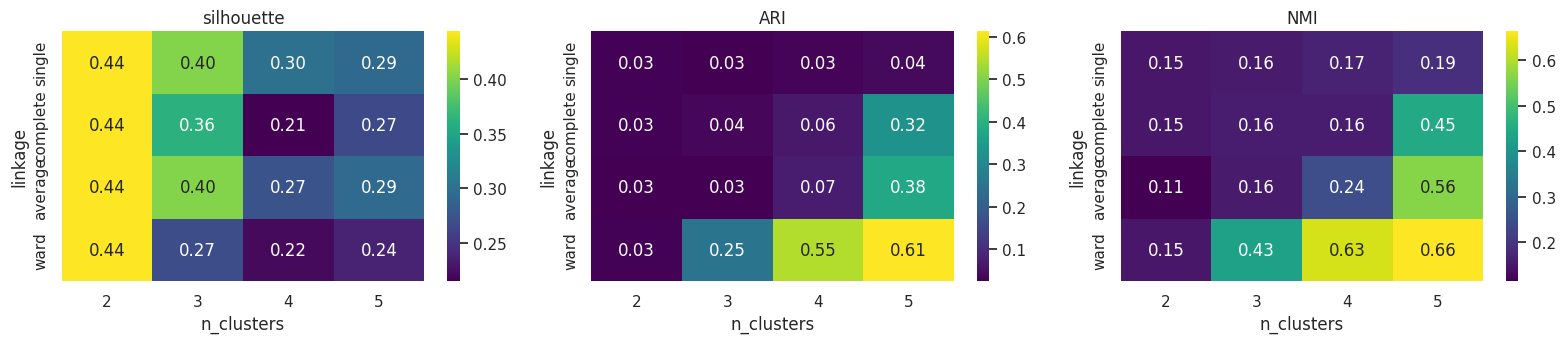

Cophenetic correlation (how faithfully the dendrogram preserves the original distances; closer to 1 is better):
  single   : 0.844
  complete : 0.801
  average  : 0.870
  ward     : 0.733


In [26]:
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet
from scipy.spatial.distance import pdist

linkages = ['single', 'complete', 'average', 'ward']; ncl = [2, 3, 4, 5]
rows, store = [], {}
for lk in linkages:
    for k in ncl:
        lab = AgglomerativeClustering(n_clusters=k, linkage=lk).fit_predict(Xs); store[(lk, k)] = lab
        rows.append(dict(linkage=lk, n_clusters=k, silhouette=silhouette_score(Xs, lab),
                         ARI=adjusted_rand_score(y, lab), NMI=normalized_mutual_info_score(y, lab),
                         cluster_sizes=sorted(np.bincount(lab).tolist(), reverse=True)))
ares = pd.DataFrame(rows); display(ares.round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 3.6))
for ax, m in zip(axes, ['silhouette', 'ARI', 'NMI']):
    sns.heatmap(ares.pivot(index='linkage', columns='n_clusters', values=m).loc[linkages], annot=True, fmt='.2f', cmap='viridis', ax=ax); ax.set_title(m)
plt.tight_layout(); plt.show()

D = pdist(Xs)
print('Cophenetic correlation (how faithfully the dendrogram preserves the original distances; closer to 1 is better):')
for lk in linkages:
    print(f'  {lk:9s}: {cophenet(linkage(Xs, lk), D)[0]:.3f}')

### Dendrogram (SciPy hierarchical workflow, Ward linkage)
`scipy.cluster.hierarchy.linkage` builds the full merge table `Z`; each row is one merge: *(cluster A, cluster B, merge distance, size of new cluster)*.
Leaf labels are the image file names, coloured by the **actual class** (the class is only used for colouring after the fact, not for building the tree).

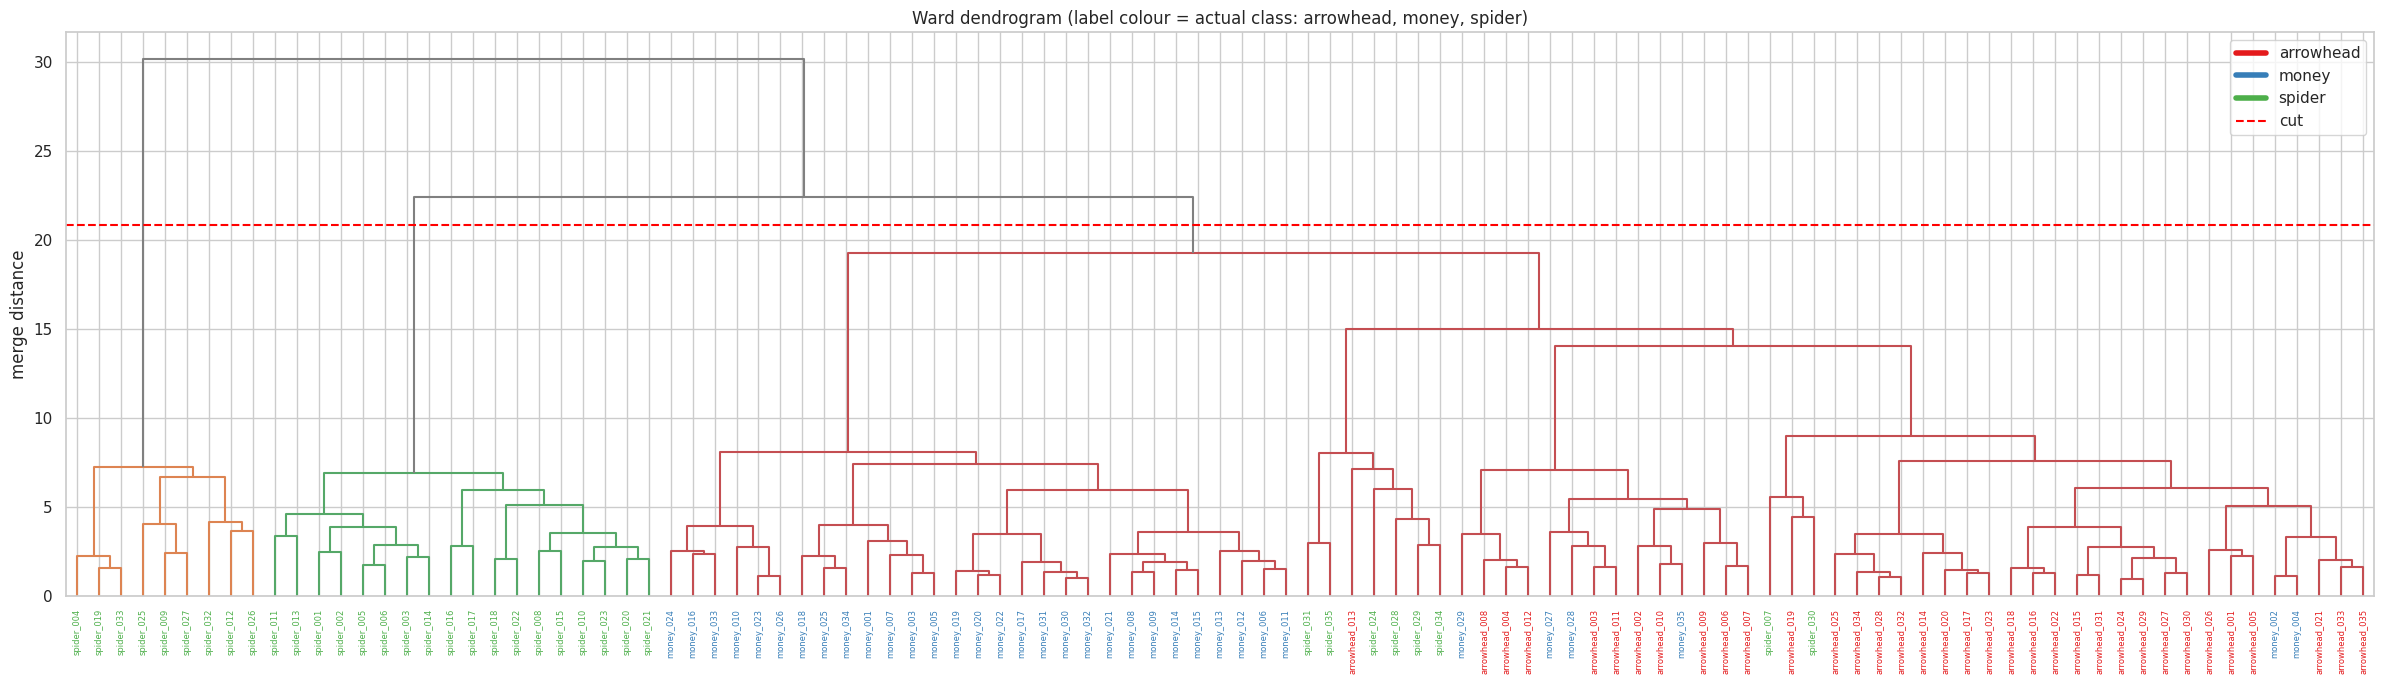

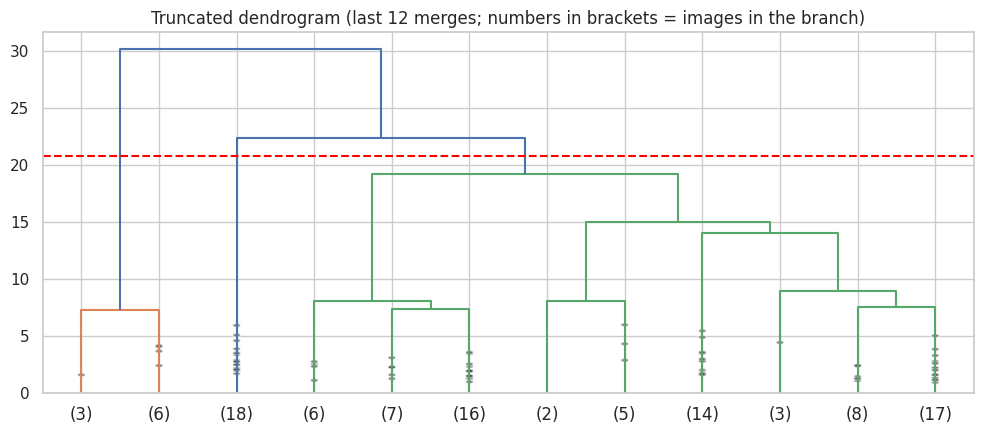

In [27]:
K_AGG = 3
Z = linkage(Xs, method='ward')
thr = (Z[-(K_AGG - 1), 2] + Z[-K_AGG, 2]) / 2          # cut between the (K-1)th and Kth last merge -> K clusters
pal = dict(zip(classes, sns.color_palette('Set1', len(classes))))

fig, ax = plt.subplots(figsize=(24, 7))
dendrogram(Z, labels=df['file_name'].str.rsplit('.', n=1).str[0].tolist(), leaf_rotation=90, leaf_font_size=6, color_threshold=thr, above_threshold_color='grey', ax=ax)
ax.axhline(thr, color='red', ls='--', label=f'cut for {K_AGG} clusters'); ax.legend()
name2cls = dict(zip(df['file_name'].str.rsplit('.', n=1).str[0], df['label']))
for t in ax.get_xmajorticklabels(): t.set_color(pal[name2cls[t.get_text()]])
ax.set_title('Ward dendrogram (label colour = actual class: ' + ', '.join(f'{c}' for c in classes) + ')'); ax.set_ylabel('merge distance')
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([0], [0], color=pal[c], lw=4, label=c) for c in classes] + [Line2D([0], [0], color='red', ls='--', label='cut')], loc='upper right')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(10, 4.5))
dendrogram(Z, truncate_mode='lastp', p=12, show_contracted=True, color_threshold=thr, ax=ax)
ax.axhline(thr, color='red', ls='--'); ax.set_title('Truncated dendrogram (last 12 merges; numbers in brackets = images in the branch)'); plt.tight_layout(); plt.show()

### Which observations / clusters are merged at which stage?

In [28]:
n = len(Xs); members = {i: [i] for i in range(n)}
for step, (a, b, h, sz) in enumerate(Z):
    members[n + step] = members[int(a)] + members[int(b)]
comp = lambda node: {k: int(v) for k, v in pd.Series(y[members[node]]).value_counts().items()}

print('EARLY merges (the most similar pairs of images):')
for step in range(5):
    a, b, h, sz = Z[step]
    print(f'  step {step + 1}: {df.file_name[int(a)]} + {df.file_name[int(b)]}  (distance {h:.2f})')
print('\nLATE merges (the top of the tree - how the big groups join):')
for step in range(n - 6, n - 1):
    a, b, h, sz = Z[step]
    print(f'  step {step + 1}: [{len(members[int(a)])} imgs {comp(int(a))}] + [{len(members[int(b)])} imgs {comp(int(b))}]  at distance {h:.2f}')

EARLY merges (the most similar pairs of images):
  step 1: arrowhead_024.jpg + arrowhead_029.jpg  (distance 0.91)
  step 2: money_030.jpg + money_032.jpg  (distance 0.96)
  step 3: arrowhead_028.jpg + arrowhead_032.jpg  (distance 1.07)
  step 4: money_023.jpg + money_026.jpg  (distance 1.10)
  step 5: money_002.jpg + money_004.jpg  (distance 1.11)

LATE merges (the top of the tree - how the big groups join):
  step 100: [14 imgs {'arrowhead': 10, 'money': 4}] + [28 imgs {'arrowhead': 24, 'spider': 2, 'money': 2}]  at distance 14.03
  step 101: [7 imgs {'spider': 6, 'arrowhead': 1}] + [42 imgs {'arrowhead': 34, 'money': 6, 'spider': 2}]  at distance 15.00
  step 102: [29 imgs {'money': 29}] + [49 imgs {'arrowhead': 35, 'spider': 8, 'money': 6}]  at distance 19.26
  step 103: [18 imgs {'spider': 18}] + [78 imgs {'money': 35, 'arrowhead': 35, 'spider': 8}]  at distance 22.41
  step 104: [9 imgs {'spider': 9}] + [96 imgs {'money': 35, 'arrowhead': 35, 'spider': 26}]  at distance 30.16


Observations per cluster (Ward, K=3): [78, 9, 18]


label,arrowhead,money,spider
agg_ward,,,
0,35,35,8
1,0,0,9
2,0,0,18


Dominant class per cluster: {0: 'arrowhead', 1: 'spider', 2: 'spider'} | purity = 0.59


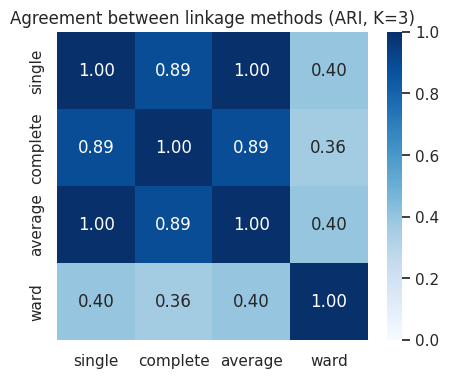

Cluster sizes (K=3):
  single    [95, 9, 1]
  complete  [93, 9, 3]
  average   [95, 9, 1]
  ward      [78, 18, 9]

Agreement K-Means vs Ward (ARI): 0.741


In [29]:
agg_labels = store[('ward', K_AGG)]
feat['agg_ward'] = agg_labels
print('Observations per cluster (Ward, K=3):', np.bincount(agg_labels).tolist())
ct_a = pd.crosstab(feat['agg_ward'], feat['label']); display(ct_a)
dom_a = ct_a.idxmax(axis=1); purity_a = ct_a.max(axis=1).sum() / ct_a.values.sum()
print('Dominant class per cluster:', dom_a.to_dict(), '| purity =', round(purity_a, 3))

ag_sil = silhouette_score(Xs, agg_labels); ag_ari = adjusted_rand_score(y, agg_labels); ag_nmi = normalized_mutual_info_score(y, agg_labels)

# how different are the linkage methods from each other? (ARI between their K=3 partitions)
M_ = pd.DataFrame([[adjusted_rand_score(store[(a, 3)], store[(b, 3)]) for b in linkages] for a in linkages], index=linkages, columns=linkages)
plt.figure(figsize=(5, 4)); sns.heatmap(M_, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1); plt.title('Agreement between linkage methods (ARI, K=3)'); plt.show()
print('Cluster sizes (K=3):'); [print(f'  {lk:9s}', sorted(np.bincount(store[(lk, 3)]).tolist(), reverse=True)) for lk in linkages]
print(f'\nAgreement K-Means vs Ward (ARI): {adjusted_rand_score(feat["kmeans"], agg_labels):.3f}')

**Interpretation (write after running):** which linkage gave the best structure and why? Single linkage often produces one huge cluster plus tiny ones (chaining effect);
Ward/complete tend to give balanced clusters. Which classes merge first at the top of the dendrogram (most similar)? Compare Ward clusters with K-Means clusters.

# Phase VI – Comparative Analysis and Final Interpretation

KNN is **supervised**, so it is judged on held-out labelled data (accuracy, precision, recall, F1). K-Means and Agglomerative are **unsupervised**: their cluster numbers are arbitrary, so
accuracy is not meaningful. They are judged with the **Silhouette Score** (internal quality, no labels) and **ARI / NMI** (external agreement with the true classes, invariant to cluster numbering).

,KNN,K-Means (K=3),"Agglomerative (Ward, K=3)"
Learning type,Supervised,Unsupervised,Unsupervised
Labels used during fitting,Yes,No,No
Accuracy on held-out labels,1.000,Not directly applicable,Not directly applicable
Macro F1 on held-out labels,1.000,Not directly applicable,Not directly applicable
Silhouette Score,Not applicable,0.311,0.268
ARI,Not applicable,0.426,0.252
NMI,Not applicable,0.574,0.427
"Purity (majority-class mapping, illustrative)",Not applicable,0.657,0.590


Robust KNN estimate (repeated 5-fold CV, all data): 0.934 +/- 0.047


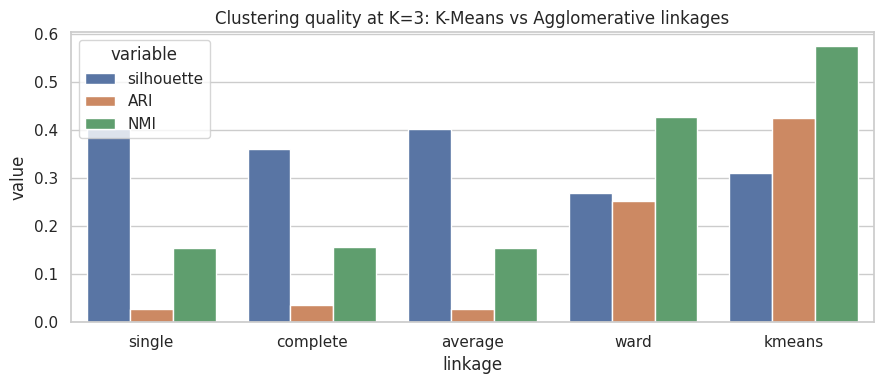

In [30]:
na = 'Not applicable'; nda = 'Not directly applicable'
cmp_tbl = pd.DataFrame({
    'KNN': ['Supervised', 'Yes', f'{knn_test_acc:.3f}', f'{knn_macro_f1:.3f}', na, na, na, na],
    'K-Means (K=3)': ['Unsupervised', 'No', nda, nda, f'{km_sil:.3f}', f'{km_ari:.3f}', f'{km_nmi:.3f}', f'{purity:.3f}'],
    'Agglomerative (Ward, K=3)': ['Unsupervised', 'No', nda, nda, f'{ag_sil:.3f}', f'{ag_ari:.3f}', f'{ag_nmi:.3f}', f'{purity_a:.3f}'],
}, index=['Learning type', 'Labels used during fitting', 'Accuracy on held-out labels', 'Macro F1 on held-out labels',
          'Silhouette Score', 'ARI', 'NMI', 'Purity (majority-class mapping, illustrative)'])
display(cmp_tbl)
print(f'Robust KNN estimate (repeated 5-fold CV, all data): {rcv.mean():.3f} +/- {rcv.std():.3f}')

sub = ares[ares.n_clusters == 3].melt(id_vars='linkage', value_vars=['silhouette', 'ARI', 'NMI'])
km_rows = pd.DataFrame({'linkage': ['kmeans'] * 3, 'variable': ['silhouette', 'ARI', 'NMI'], 'value': [km_sil, km_ari, km_nmi]})
plt.figure(figsize=(9, 4)); sns.barplot(data=pd.concat([sub, km_rows]), x='linkage', y='value', hue='variable')
plt.title('Clustering quality at K=3: K-Means vs Agglomerative linkages'); plt.tight_layout(); plt.show()

### Main observations (complete in your own words)
* **KNN:** how accurate, which classes confused, effect of K/metric, how it compares with the repeated-CV estimate.
* **K-Means:** best K by elbow/silhouette, how well clusters match leaf types (ARI/NMI), which images fell in unexpected clusters and why.
* **Agglomerative:** best linkage, dendrogram structure, differences between linkages.
* **Why supervised > unsupervised here (or not):** KNN uses the labels, clustering must discover structure from features only; a high ARI would mean the features themselves carry the class structure.

### Limitations (adapt to what you actually observed)
* Small dataset (~100 images) → test results are noisy; one extra misclassification changes accuracy by several percent.
* Leaves from a limited number of plants (all from one garden) → less variation than real-world data.
* Segmentation by greenness can fail on yellow/white-patched leaves or green backgrounds (grass), which affects shape and colour features.
* Lighting/background changes shift colour features; clustering may group by photo conditions instead of plant type.
* Hand-crafted features (colour/texture/shape summaries) lose information; learned features (e.g. CNN embeddings) would likely separate similar leaves better.
* K-Means assumes round clusters of similar size; Agglomerative is sensitive to linkage choice and to outliers.

### Conclusion
Summarise which algorithm and configuration worked best, and what would improve the results (more images, more plants, controlled lighting, better segmentation, additional features).